Wind  =>  OMNI
2024-12-16 12:00:00 2024-12-18 06:00:00 0
2024-12-07 07:00:00 2024-12-09 10:00:00 0
2024-11-28 10:00:00 2024-11-30 09:00:00 0
2024-11-13 11:00:00 2024-11-15 08:00:00 0
2024-11-09 06:00:00 2024-11-11 03:00:00 0
2024-11-08 06:00:00 2024-11-10 04:00:00 0
2024-11-07 18:00:00 2024-11-09 11:00:00 0
2024-10-26 00:00:00 2024-10-28 01:00:00 0
2024-10-09 23:00:00 2024-10-12 02:00:00 0
2024-10-07 06:00:00 2024-10-09 01:00:00 0
2024-10-06 20:00:00 2024-10-08 12:00:00 0
2024-10-05 15:00:00 2024-10-07 17:00:00 0
2024-09-16 07:00:00 2024-09-18 04:00:00 0
2024-09-11 16:00:00 2024-09-13 16:00:00 0
2024-09-11 11:00:00 2024-09-13 00:00:00 0
2024-08-30 20:00:00 2024-09-02 01:00:00 0
2024-08-26 16:00:00 2024-08-30 08:00:00 0
2024-08-16 22:00:00 2024-08-19 01:00:00 0
2024-08-09 20:00:00 2024-08-14 10:00:00 0
2024-08-04 05:00:00 2024-08-05 22:00:00 0
2024-08-03 16:00:00 2024-08-05 08:00:00 0
2024-07-23 04:00:00 2024-07-25 05:00:00 0
2024-07-20 22:00:00 2024-07-23 13:00:00 0
2024-07-15 05:00:00

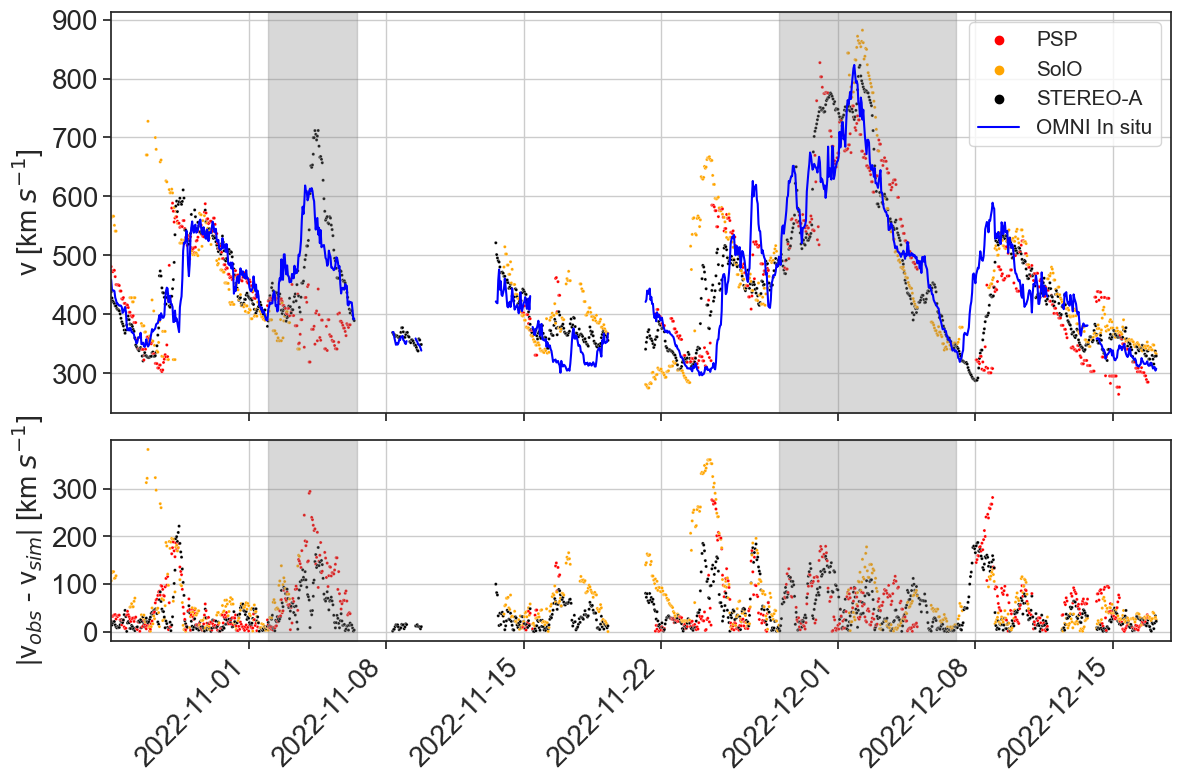

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import matplotlib
import seaborn as sns
from P2D import dataloader
from P2D.utils import spacecraft_ID
import numpy as np

sns.set(
    style="ticks",
    palette="muted",
    rc={
        "axes.labelsize": 20,    # Axis label size
        "xtick.labelsize": 20,   # X-axis tick label size
        "ytick.labelsize": 20,   # Y-axis tick label size
        "font.size": 13,         # Overall font size
        "figure.dpi": 100,        # Paper -> 1000
        "legend.fontsize": 15 # Size of legend
    }
)

#time_series = pd.read_parquet('model_results_omni_1dsmoothed_inelastic_100dwindow.parquet')
time_series = pd.read_parquet('model_results_omni_2hsmoothed_inelastic_100dwindow_part5.parquet')
time_series['Persistence_time'] = (time_series.index - time_series['Time']).dt.total_seconds()/3600/24
time_series = time_series[time_series['Persistence_time']<27]
time_series = time_series[time_series['Spacecraft_ID']!=6]
time_series = time_series['2022-10-25':'2022-12-17']

start_time = time_series.index.min().strftime('%Y-%m-%d-%H:%M')
end_time = time_series.index.max().strftime('%Y-%m-%d-%H:%M')

# Load spacecraft data
spacecraft_data = dataloader.load(spacecraft='OMNI', timerange=[start_time, end_time], cadence='1h')
spacecraft_data = spacecraft_data[~spacecraft_data.index.duplicated(keep='first')]

#time_series['Total_time_difference'] = (time_series['Encounter_time'] - time_series['Start_time_of_parcel']).dt.total_seconds()/3600/24
#time_series = time_series.copy().sort_values(by='Total_time_difference', ascending=True)
# deduped = time_series[~time_series.duplicated(subset='Time',
#                          keep='first'
#                     )].copy()


remove_cmes=True
if remove_cmes:
    cmes = pd.read_excel('HELIO4CAST_ICMECAT_v23 (1).xlsx')

    spacecraft = ['Wind', 'STEREO-A', 'SolarOrbiter', 'PSP']
    my_spacecraft = ['OMNI', 'STEREO-A', 'SolO', 'PSP']

    for i, sc in enumerate(spacecraft):
        print(sc, ' => ', my_spacecraft[i])
        start_times = pd.to_datetime(cmes.loc[cmes['sc_insitu']==sc]['icme_start_time']).reset_index()['icme_start_time'] - pd.Timedelta(value='16h')
        end_times = pd.to_datetime(cmes.loc[cmes['sc_insitu']==sc]['mo_end_time']).reset_index()['mo_end_time'] + pd.Timedelta(value='16h')

        mask = time_series['Spacecraft_ID']==spacecraft_ID(my_spacecraft[i], ID_number=True)

        for j in range(len(start_times)):
            
            start = start_times[j].round("h").tz_localize(None)
            end = end_times[j].round("h").tz_localize(None)

            time_mask = (mask.index < end) & (mask.index > start)


            print(start, end, time_mask.sum())
            time_series[time_mask] = np.nan
if remove_cmes:
    cmes = pd.read_excel('HELIO4CAST_ICMECAT_v23 (1).xlsx')

    spacecraft = ['Wind', 'STEREO-A', 'SolarOrbiter', 'PSP']
    my_spacecraft = ['OMNI', 'STEREO-A', 'SolO', 'PSP']

    for i, sc in enumerate(spacecraft):
        print(sc, ' => ', my_spacecraft[i])
        start_times = pd.to_datetime(cmes.loc[cmes['sc_insitu']==sc]['icme_start_time']).reset_index()['icme_start_time'] - pd.Timedelta(value='16h')
        end_times = pd.to_datetime(cmes.loc[cmes['sc_insitu']==sc]['mo_end_time']).reset_index()['mo_end_time'] + pd.Timedelta(value='16h')

        mask = spacecraft_data['Spacecraft_ID']==spacecraft_ID(my_spacecraft[i], ID_number=True)

        for j in range(len(start_times)):
            
            start = start_times[j].round("h").tz_localize(None)
            end = end_times[j].round("h").tz_localize(None)

            time_mask = (mask.index < end) & (mask.index > start)


            print(start, end, time_mask.sum())
            spacecraft_data[time_mask] = np.nan


time_series['ΔV'] = time_series['V'] - time_series.index.map(spacecraft_data['V'])

time_series['V_MAE'] = abs(time_series['V'] - time_series.index.map(spacecraft_data['V']))

# Set up figure
fig, ax = plt.subplots(2,1,figsize=(12, 8), sharex=True, height_ratios=[2,1])
import matplotlib.dates as mdates

# Define custom colors and label mapping
custom_palette = {
    6: 'blue',
    7: 'darkred',
    2: 'orange',
    4: 'black',
    1: 'red',
}
label_dict = {
    6: 'OMNI',
    7: 'MAVEN',
    2: 'SolO',
    4: 'STEREO-A',
    1: 'PSP',
}
# Define what counts as a "gap" (e.g., 3 hours)
max_gap = np.timedelta64(3, 'h')

time = spacecraft_data.index
values = spacecraft_data['V'].copy()

# Insert NaN where time gaps exceed threshold
time_diffs = time.to_series().diff().values
gap_indices = np.where(time_diffs > max_gap)[0]
values.iloc[gap_indices] = np.nan

ax[0].plot(time, values, color='blue', label='OMNI in situ')

# Plot scatterplot
sns.scatterplot(
    data=time_series, x=time_series.index, y='V', 
    hue='Spacecraft_ID', palette=custom_palette, ax=ax[0], s=5
)


# Plot scatterplot
# sns.scatterplot(
#     data=time_series, x=time_series.index, y='ΔV', 
#     hue='Spacecraft_ID', palette=custom_palette, ax=ax[1], s=5, legend=False
# )
# Plot scatterplot
sns.scatterplot(
    data=time_series, x=time_series.index, y='V_MAE', 
    hue='Spacecraft_ID', palette=custom_palette, ax=ax[1], s=5, legend=False
)


# Customize legend labels
handles, labels = ax[0].get_legend_handles_labels()
new_labels = [label_dict.get(int(float(lbl)), lbl) for lbl in labels[1:]]  # Skip hue name
ax[0].legend(handles[1:] + [handles[0]], new_labels + ['OMNI In situ'])

# Beautify time axis
ax[0].xaxis.set_major_locator(mdates.AutoDateLocator())  # or WeekLocator(), AutoDateLocator()
ax[0].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))  # or '%b %Y' for abbreviated months
plt.setp(ax[1].get_xticklabels(), rotation=45, ha='right')  # Rotate for readability


ax[0].set_ylabel(r'v [km $s^{-1}$]')
ax[0].set_xlim(time_series.index.min(), time_series.index.max())

ax0_ylims = ax[0].get_ylim()
ax1_ylims = ax[1].get_ylim()

first_stream = ['2022-11-02', '2022-11-06 12:00']
second_stream = ['2022-11-28', '2022-12-07 00:00']
alpha=0.3
ax[0].fill_between(x = first_stream, y1 = ax0_ylims[0], y2 = ax0_ylims[1], color = 'grey', alpha=alpha)
ax[1].fill_between(x = first_stream, y1 = ax1_ylims[0], y2 = ax1_ylims[1], color = 'grey', alpha=alpha)

ax[0].fill_between(x = second_stream, y1 = ax0_ylims[0], y2 = ax0_ylims[1], color = 'grey', alpha=alpha)
ax[1].fill_between(x = second_stream, y1 = ax1_ylims[0], y2 = ax1_ylims[1], color = 'grey', alpha=alpha)


ax[0].set_ylim(ax0_ylims)
ax[1].set_ylim(ax1_ylims)
ax[1].set_yticks([0,100,200,300])

ax[0].get_ylim
ax[1].set_ylabel(r'|v$_{obs}$ - v$_{sim}$| [km $s^{-1}$]')
#ax[2].set_ylabel('AE [km/s]')
# Final touches
ax[0].grid()
ax[1].grid()
ax[1].set_xlabel('')
plt.tight_layout()
plt.show()


Wind  =>  OMNI
2024-12-16 12:00:00 2024-12-18 06:00:00 0
2024-12-07 07:00:00 2024-12-09 10:00:00 0
2024-11-28 10:00:00 2024-11-30 09:00:00 0
2024-11-13 11:00:00 2024-11-15 08:00:00 0
2024-11-09 06:00:00 2024-11-11 03:00:00 0
2024-11-08 06:00:00 2024-11-10 04:00:00 0
2024-11-07 18:00:00 2024-11-09 11:00:00 0
2024-10-26 00:00:00 2024-10-28 01:00:00 0
2024-10-09 23:00:00 2024-10-12 02:00:00 0
2024-10-07 06:00:00 2024-10-09 01:00:00 0
2024-10-06 20:00:00 2024-10-08 12:00:00 0
2024-10-05 15:00:00 2024-10-07 17:00:00 0
2024-09-16 07:00:00 2024-09-18 04:00:00 0
2024-09-11 16:00:00 2024-09-13 16:00:00 0
2024-09-11 11:00:00 2024-09-13 00:00:00 0
2024-08-30 20:00:00 2024-09-02 01:00:00 0
2024-08-26 16:00:00 2024-08-30 08:00:00 0
2024-08-16 22:00:00 2024-08-19 01:00:00 0
2024-08-09 20:00:00 2024-08-14 10:00:00 0
2024-08-04 05:00:00 2024-08-05 22:00:00 0
2024-08-03 16:00:00 2024-08-05 08:00:00 0
2024-07-23 04:00:00 2024-07-25 05:00:00 0
2024-07-20 22:00:00 2024-07-23 13:00:00 0
2024-07-15 05:00:00

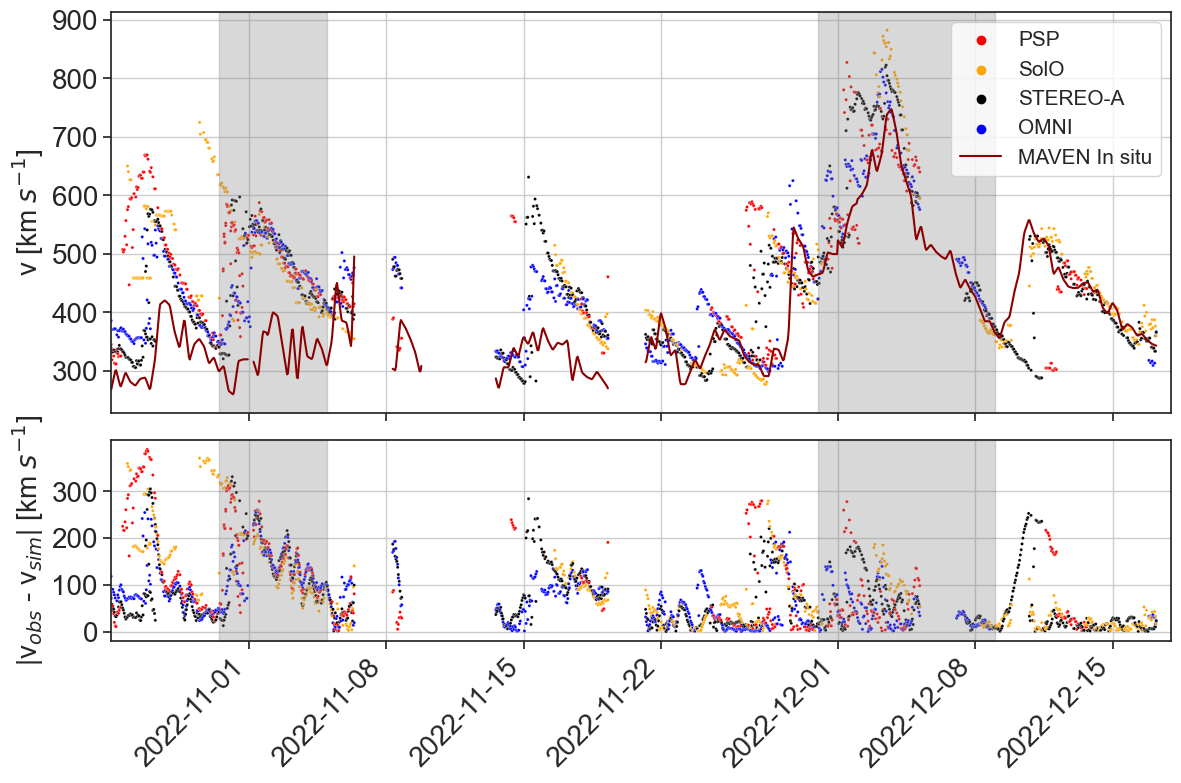

In [17]:
import matplotlib.pyplot as plt
import pandas as pd
import matplotlib
import seaborn as sns
from P2D import dataloader
from P2D.utils import spacecraft_ID
import numpy as np

sns.set(
    style="ticks",
    palette="muted",
    rc={
        "axes.labelsize": 20,    # Axis label size
        "xtick.labelsize": 20,   # X-axis tick label size
        "ytick.labelsize": 20,   # Y-axis tick label size
        "font.size": 13,         # Overall font size
        "figure.dpi": 100,        # Paper -> 1000
        "legend.fontsize": 15 # Size of legend
    }
)

#time_series = pd.read_parquet('model_results_omni_1dsmoothed_inelastic_100dwindow.parquet')
time_series = pd.read_parquet('model_results_maven_2hsmoothed_inelastic_100dwindow_part3.parquet')
#time_series = pd.read_parquet('model_results_maven_matrix.parquet')
time_series['Persistence_time'] = (time_series.index - time_series['Time']).dt.total_seconds()/3600/24
time_series = time_series[time_series['Persistence_time']<27]
time_series = time_series[time_series['Spacecraft_ID']!=7]
time_series = time_series['2022-10-25':'2022-12-17']

start_time = time_series.index.min().strftime('%Y-%m-%d-%H:%M')
end_time = time_series.index.max().strftime('%Y-%m-%d-%H:%M')

# Load spacecraft data
spacecraft_data = dataloader.load(spacecraft='MAVEN', timerange=[start_time, end_time], cadence='1h')
spacecraft_data = spacecraft_data[~spacecraft_data.index.duplicated(keep='first')]

#time_series['Total_time_difference'] = (time_series['Encounter_time'] - time_series['Start_time_of_parcel']).dt.total_seconds()/3600/24
#time_series = time_series.copy().sort_values(by='Total_time_difference', ascending=True)
# deduped = time_series[~time_series.duplicated(subset='Time',
#                          keep='first'
#                     )].copy()


remove_cmes=True
if remove_cmes:
    cmes = pd.read_excel('HELIO4CAST_ICMECAT_v23 (1).xlsx')

    spacecraft = ['Wind', 'STEREO-A', 'SolarOrbiter', 'PSP']
    my_spacecraft = ['OMNI', 'STEREO-A', 'SolO', 'PSP']

    for i, sc in enumerate(spacecraft):
        print(sc, ' => ', my_spacecraft[i])
        start_times = pd.to_datetime(cmes.loc[cmes['sc_insitu']==sc]['icme_start_time']).reset_index()['icme_start_time'] - pd.Timedelta(value='16h')
        end_times = pd.to_datetime(cmes.loc[cmes['sc_insitu']==sc]['mo_end_time']).reset_index()['mo_end_time'] + pd.Timedelta(value='16h')

        mask = time_series['Spacecraft_ID']==spacecraft_ID(my_spacecraft[i], ID_number=True)

        for j in range(len(start_times)):
            
            start = start_times[j].round("h").tz_localize(None)
            end = end_times[j].round("h").tz_localize(None)

            time_mask = (mask.index < end) & (mask.index > start)


            print(start, end, time_mask.sum())
            time_series[time_mask] = np.nan
if remove_cmes:
    cmes = pd.read_excel('HELIO4CAST_ICMECAT_v23 (1).xlsx')

    spacecraft = ['Wind', 'STEREO-A', 'SolarOrbiter', 'PSP']
    my_spacecraft = ['OMNI', 'STEREO-A', 'SolO', 'PSP']

    for i, sc in enumerate(spacecraft):
        print(sc, ' => ', my_spacecraft[i])
        start_times = pd.to_datetime(cmes.loc[cmes['sc_insitu']==sc]['icme_start_time']).reset_index()['icme_start_time'] - pd.Timedelta(value='16h')
        end_times = pd.to_datetime(cmes.loc[cmes['sc_insitu']==sc]['mo_end_time']).reset_index()['mo_end_time'] + pd.Timedelta(value='16h')

        mask = spacecraft_data['Spacecraft_ID']==spacecraft_ID(my_spacecraft[i], ID_number=True)

        for j in range(len(start_times)):
            
            start = start_times[j].round("h").tz_localize(None)
            end = end_times[j].round("h").tz_localize(None)

            time_mask = (mask.index < end) & (mask.index > start)


            print(start, end, time_mask.sum())
            spacecraft_data[time_mask] = np.nan


time_series['ΔV'] = time_series['V'] - time_series.index.map(spacecraft_data['V'])

time_series['V_MAE'] = abs(time_series['V'] - time_series.index.map(spacecraft_data['V']))

# Set up figure
fig, ax = plt.subplots(2,1,figsize=(12, 8), sharex=True, height_ratios=[2,1])
import matplotlib.dates as mdates

# Define custom colors and label mapping
custom_palette = {
    6: 'blue',
    7: 'darkred',
    2: 'orange',
    4: 'black',
    1: 'red',
}
label_dict = {
    6: 'OMNI',
    7: 'MAVEN',
    2: 'SolO',
    4: 'STEREO-A',
    1: 'PSP',
}
# Define what counts as a "gap" (e.g., 3 hours)
max_gap = np.timedelta64(3, 'h')

time = spacecraft_data.index
values = spacecraft_data['V'].copy()

# Insert NaN where time gaps exceed threshold
time_diffs = time.to_series().diff().values
gap_indices = np.where(time_diffs > max_gap)[0]
values.iloc[gap_indices] = np.nan

ax[0].plot(time, values, color='darkred', label='MAVEN in situ')

# Plot scatterplot
sns.scatterplot(
    data=time_series, x=time_series.index, y='V', 
    hue='Spacecraft_ID', palette=custom_palette, ax=ax[0], s=5
)


# Plot scatterplot
# sns.scatterplot(
#     data=time_series, x=time_series.index, y='ΔV', 
#     hue='Spacecraft_ID', palette=custom_palette, ax=ax[1], s=5, legend=False
# )
# Plot scatterplot
sns.scatterplot(
    data=time_series, x=time_series.index, y='V_MAE', 
    hue='Spacecraft_ID', palette=custom_palette, ax=ax[1], s=5, legend=False
)


# Customize legend labels
handles, labels = ax[0].get_legend_handles_labels()
new_labels = [label_dict.get(int(float(lbl)), lbl) for lbl in labels[1:]]  # Skip hue name
ax[0].legend(handles[1:] + [handles[0]], new_labels + ['MAVEN In situ'])

# Beautify time axis
ax[0].xaxis.set_major_locator(mdates.AutoDateLocator())  # or WeekLocator(), AutoDateLocator()
ax[0].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))  # or '%b %Y' for abbreviated months
plt.setp(ax[1].get_xticklabels(), rotation=45, ha='right')  # Rotate for readability


ax[0].set_ylabel(r'v [km $s^{-1}$]')
ax[0].set_xlim(time_series.index.min(), time_series.index.max())

ax0_ylims = ax[0].get_ylim()
ax1_ylims = ax[1].get_ylim()

first_stream = ['2022-10-30 12:00', '2022-11-05 00:00']
second_stream = ['2022-11-30', '2022-12-09 00:00']
alpha=0.3
ax[0].fill_between(x = first_stream, y1 = ax0_ylims[0], y2 = ax0_ylims[1], color = 'grey', alpha=alpha)
ax[1].fill_between(x = first_stream, y1 = ax1_ylims[0], y2 = ax1_ylims[1], color = 'grey', alpha=alpha)

ax[0].fill_between(x = second_stream, y1 = ax0_ylims[0], y2 = ax0_ylims[1], color = 'grey', alpha=alpha)
ax[1].fill_between(x = second_stream, y1 = ax1_ylims[0], y2 = ax1_ylims[1], color = 'grey', alpha=alpha)


ax[0].set_ylim(ax0_ylims)
ax[1].set_ylim(ax1_ylims)
ax[1].set_yticks([0,100,200,300])

ax[0].get_ylim
#ax[1].set_ylabel(r'AE [km $s^{-1}$]')
ax[1].set_ylabel(r'|v$_{obs}$ - v$_{sim}$| [km $s^{-1}$]')
#ax[2].set_ylabel('AE [km/s]')
# Final touches
ax[0].grid()
ax[1].grid()
ax[1].set_xlabel('')
plt.tight_layout()
plt.show()


Wind  =>  OMNI
2024-12-16 12:00:00 2024-12-18 06:00:00 0
2024-12-07 07:00:00 2024-12-09 10:00:00 0
2024-11-28 10:00:00 2024-11-30 09:00:00 0
2024-11-13 11:00:00 2024-11-15 08:00:00 0
2024-11-09 06:00:00 2024-11-11 03:00:00 0
2024-11-08 06:00:00 2024-11-10 04:00:00 0
2024-11-07 18:00:00 2024-11-09 11:00:00 0
2024-10-26 00:00:00 2024-10-28 01:00:00 0
2024-10-09 23:00:00 2024-10-12 02:00:00 0
2024-10-07 06:00:00 2024-10-09 01:00:00 0
2024-10-06 20:00:00 2024-10-08 12:00:00 0
2024-10-05 15:00:00 2024-10-07 17:00:00 0
2024-09-16 07:00:00 2024-09-18 04:00:00 0
2024-09-11 16:00:00 2024-09-13 16:00:00 0
2024-09-11 11:00:00 2024-09-13 00:00:00 0
2024-08-30 20:00:00 2024-09-02 01:00:00 0
2024-08-26 16:00:00 2024-08-30 08:00:00 0
2024-08-16 22:00:00 2024-08-19 01:00:00 0
2024-08-09 20:00:00 2024-08-14 10:00:00 0
2024-08-04 05:00:00 2024-08-05 22:00:00 0
2024-08-03 16:00:00 2024-08-05 08:00:00 0
2024-07-23 04:00:00 2024-07-25 05:00:00 0
2024-07-20 22:00:00 2024-07-23 13:00:00 0
2024-07-15 05:00:00

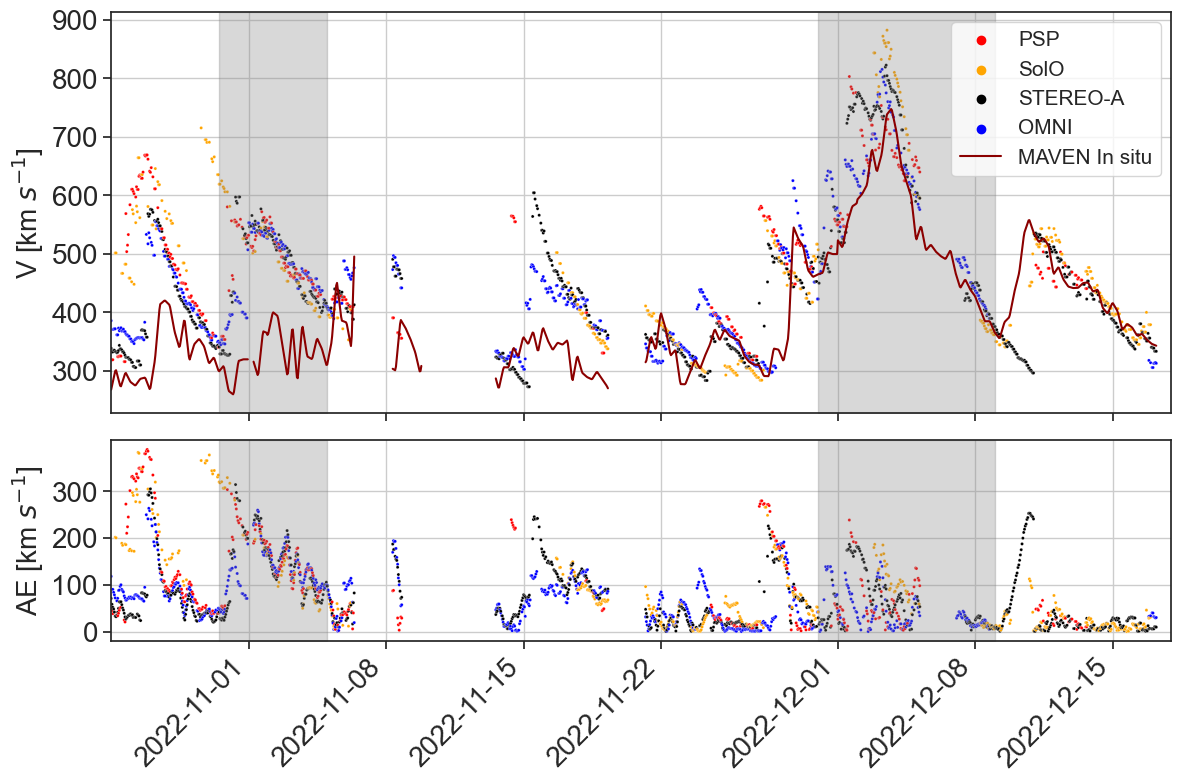

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import matplotlib
import seaborn as sns
from P2D import dataloader
from P2D.utils import spacecraft_ID
import numpy as np

sns.set(
    style="ticks",
    palette="muted",
    rc={
        "axes.labelsize": 20,    # Axis label size
        "xtick.labelsize": 20,   # X-axis tick label size
        "ytick.labelsize": 20,   # Y-axis tick label size
        "font.size": 13,         # Overall font size
        "figure.dpi": 100,        # Paper -> 1000
        "legend.fontsize": 15 # Size of legend
    }
)

#time_series = pd.read_parquet('model_results_omni_1dsmoothed_inelastic_100dwindow.parquet')
time_series = pd.read_parquet('model_cutouts/model_results_maven_2h_smoothed_inelastic_100dwindow_part5.parquet')
#time_series = pd.read_parquet('model_results_maven_matrix.parquet')
time_series['Persistence_time'] = (time_series.index - time_series['Time']).dt.total_seconds()/3600/24
time_series = time_series[time_series['Persistence_time']<27]
time_series = time_series[time_series['Spacecraft_ID']!=7]
time_series = time_series['2022-10-25':'2022-12-17']

start_time = time_series.index.min().strftime('%Y-%m-%d-%H:%M')
end_time = time_series.index.max().strftime('%Y-%m-%d-%H:%M')

# Load spacecraft data
spacecraft_data = dataloader.load(spacecraft='MAVEN', timerange=[start_time, end_time], cadence='1h')
spacecraft_data = spacecraft_data[~spacecraft_data.index.duplicated(keep='first')]

#time_series['Total_time_difference'] = (time_series['Encounter_time'] - time_series['Start_time_of_parcel']).dt.total_seconds()/3600/24
#time_series = time_series.copy().sort_values(by='Total_time_difference', ascending=True)
# deduped = time_series[~time_series.duplicated(subset='Time',
#                          keep='first'
#                     )].copy()


remove_cmes=True
if remove_cmes:
    cmes = pd.read_excel('HELIO4CAST_ICMECAT_v23 (1).xlsx')

    spacecraft = ['Wind', 'STEREO-A', 'SolarOrbiter', 'PSP']
    my_spacecraft = ['OMNI', 'STEREO-A', 'SolO', 'PSP']

    for i, sc in enumerate(spacecraft):
        print(sc, ' => ', my_spacecraft[i])
        start_times = pd.to_datetime(cmes.loc[cmes['sc_insitu']==sc]['icme_start_time']).reset_index()['icme_start_time'] - pd.Timedelta(value='16h')
        end_times = pd.to_datetime(cmes.loc[cmes['sc_insitu']==sc]['mo_end_time']).reset_index()['mo_end_time'] + pd.Timedelta(value='16h')

        mask = time_series['Spacecraft_ID']==spacecraft_ID(my_spacecraft[i], ID_number=True)

        for j in range(len(start_times)):
            
            start = start_times[j].round("h").tz_localize(None)
            end = end_times[j].round("h").tz_localize(None)

            time_mask = (mask.index < end) & (mask.index > start)


            print(start, end, time_mask.sum())
            time_series[time_mask] = np.nan
if remove_cmes:
    cmes = pd.read_excel('HELIO4CAST_ICMECAT_v23 (1).xlsx')

    spacecraft = ['Wind', 'STEREO-A', 'SolarOrbiter', 'PSP']
    my_spacecraft = ['OMNI', 'STEREO-A', 'SolO', 'PSP']

    for i, sc in enumerate(spacecraft):
        print(sc, ' => ', my_spacecraft[i])
        start_times = pd.to_datetime(cmes.loc[cmes['sc_insitu']==sc]['icme_start_time']).reset_index()['icme_start_time'] - pd.Timedelta(value='16h')
        end_times = pd.to_datetime(cmes.loc[cmes['sc_insitu']==sc]['mo_end_time']).reset_index()['mo_end_time'] + pd.Timedelta(value='16h')

        mask = spacecraft_data['Spacecraft_ID']==spacecraft_ID(my_spacecraft[i], ID_number=True)

        for j in range(len(start_times)):
            
            start = start_times[j].round("h").tz_localize(None)
            end = end_times[j].round("h").tz_localize(None)

            time_mask = (mask.index < end) & (mask.index > start)


            print(start, end, time_mask.sum())
            spacecraft_data[time_mask] = np.nan


time_series['ΔV'] = time_series['V'] - time_series.index.map(spacecraft_data['V'])

time_series['V_MAE'] = abs(time_series['V'] - time_series.index.map(spacecraft_data['V']))

# Set up figure
fig, ax = plt.subplots(2,1,figsize=(12, 8), sharex=True, height_ratios=[2,1])
import matplotlib.dates as mdates

# Define custom colors and label mapping
custom_palette = {
    6: 'blue',
    7: 'darkred',
    2: 'orange',
    4: 'black',
    1: 'red',
}
label_dict = {
    6: 'OMNI',
    7: 'MAVEN',
    2: 'SolO',
    4: 'STEREO-A',
    1: 'PSP',
}
# Define what counts as a "gap" (e.g., 3 hours)
max_gap = np.timedelta64(3, 'h')

time = spacecraft_data.index
values = spacecraft_data['V'].copy()

# Insert NaN where time gaps exceed threshold
time_diffs = time.to_series().diff().values
gap_indices = np.where(time_diffs > max_gap)[0]
values.iloc[gap_indices] = np.nan

ax[0].plot(time, values, color='darkred', label='MAVEN in situ')

# Plot scatterplot
sns.scatterplot(
    data=time_series, x=time_series.index, y='V', 
    hue='Spacecraft_ID', palette=custom_palette, ax=ax[0], s=5
)


# Plot scatterplot
# sns.scatterplot(
#     data=time_series, x=time_series.index, y='ΔV', 
#     hue='Spacecraft_ID', palette=custom_palette, ax=ax[1], s=5, legend=False
# )
# Plot scatterplot
sns.scatterplot(
    data=time_series, x=time_series.index, y='V_MAE', 
    hue='Spacecraft_ID', palette=custom_palette, ax=ax[1], s=5, legend=False
)


# Customize legend labels
handles, labels = ax[0].get_legend_handles_labels()
new_labels = [label_dict.get(int(float(lbl)), lbl) for lbl in labels[1:]]  # Skip hue name
ax[0].legend(handles[1:] + [handles[0]], new_labels + ['MAVEN In situ'])

# Beautify time axis
ax[0].xaxis.set_major_locator(mdates.AutoDateLocator())  # or WeekLocator(), AutoDateLocator()
ax[0].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))  # or '%b %Y' for abbreviated months
plt.setp(ax[1].get_xticklabels(), rotation=45, ha='right')  # Rotate for readability


ax[0].set_ylabel(r'V [km $s^{-1}$]')
ax[0].set_xlim(time_series.index.min(), time_series.index.max())

ax0_ylims = ax[0].get_ylim()
ax1_ylims = ax[1].get_ylim()

first_stream = ['2022-10-30 12:00', '2022-11-05 00:00']
second_stream = ['2022-11-30', '2022-12-09 00:00']
alpha=0.3
ax[0].fill_between(x = first_stream, y1 = ax0_ylims[0], y2 = ax0_ylims[1], color = 'grey', alpha=alpha)
ax[1].fill_between(x = first_stream, y1 = ax1_ylims[0], y2 = ax1_ylims[1], color = 'grey', alpha=alpha)

ax[0].fill_between(x = second_stream, y1 = ax0_ylims[0], y2 = ax0_ylims[1], color = 'grey', alpha=alpha)
ax[1].fill_between(x = second_stream, y1 = ax1_ylims[0], y2 = ax1_ylims[1], color = 'grey', alpha=alpha)


ax[0].set_ylim(ax0_ylims)
ax[1].set_ylim(ax1_ylims)
ax[1].set_yticks([0,100,200,300])

ax[0].get_ylim
ax[1].set_ylabel(r'AE [km $s^{-1}$]')
#ax[2].set_ylabel('AE [km/s]')
# Final touches
ax[0].grid()
ax[1].grid()
ax[1].set_xlabel('')
plt.tight_layout()
plt.show()


                                   Time         N           V  CARR_LON_RAD  \
Encounter_time                                                                
2014-03-19 19:00:00 2014-03-19 19:00:00   8.43000  302.343784      4.274567   
2014-03-19 20:00:00 2014-03-19 20:00:00   9.01000  302.278755      4.264814   
2014-03-19 21:00:00 2014-03-19 21:00:00   9.59000  302.677925      4.255062   
2014-03-19 22:00:00 2014-03-19 22:00:00   9.40750  302.031663      4.245310   
2014-03-19 23:00:00 2014-03-19 23:00:00   8.64000  302.260976      4.235557   
...                                 ...       ...         ...           ...   
2024-06-19 18:00:00 2024-06-19 18:00:00   3.98000  584.700012      2.349393   
2024-07-16 23:00:00 2024-07-16 23:00:00  17.68875  300.049999      2.349393   
2024-08-13 04:00:00 2024-08-13 04:00:00  30.58750  474.449997      2.349393   
2024-10-06 16:00:00 2024-10-06 16:00:00   4.80000  383.987495      2.349393   
2024-10-06 17:00:00 2024-10-06 17:00:00   4.80000  3

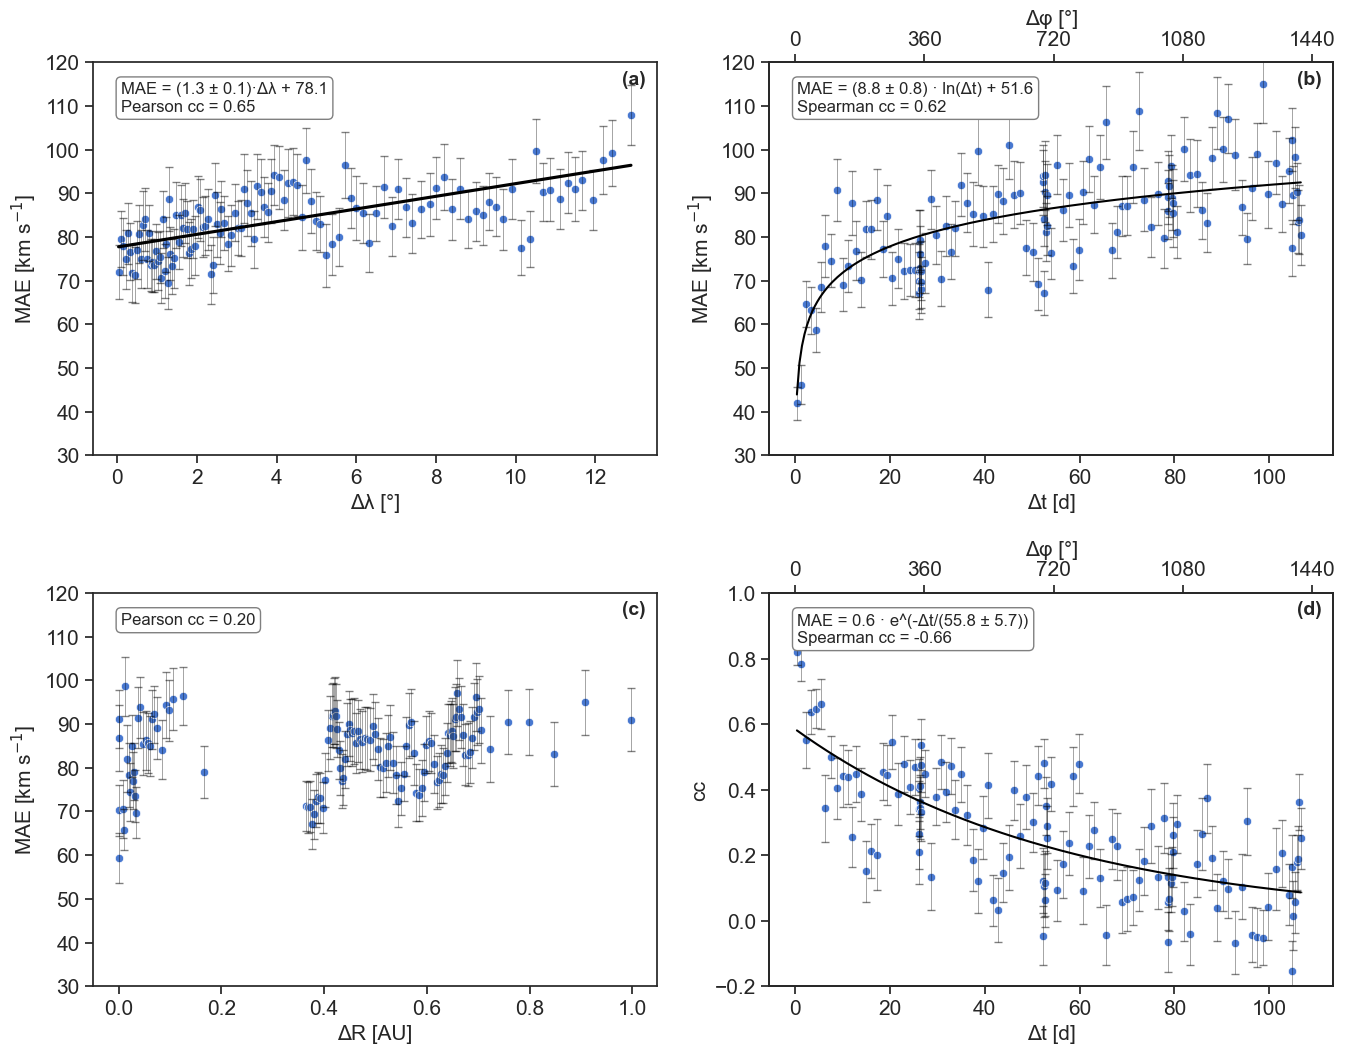

In [8]:
import pandas as pd
import seaborn as sns
from P2D import dataloader
from P2D import P2D_plots
import matplotlib.pyplot as plt
from P2D.utils import spacecraft_ID
import numpy as np
from scipy.stats import linregress, spearmanr
sns.set(
    style="ticks",
    palette="muted",
    rc={
        "axes.labelsize": 15,    # Axis label size
        "xtick.labelsize": 15,   # X-axis tick label size
        "ytick.labelsize": 15,   # Y-axis tick label size
        "font.size": 13,         # Overall font size
        "figure.dpi": 100,        # Dots per inch for figure quality
        "legend.fontsize": 15 # Size of legend
    }
)


# MAVEN

# spacecraft_to_compare = 'MAVEN'

# res1 = pd.read_parquet('model_results_maven_2hsmoothed_inelastic_100dwindow_part1.parquet')
# res2 = pd.read_parquet('model_results_maven_2hsmoothed_inelastic_100dwindow_part2.parquet')
# res3 = pd.read_parquet('model_results_maven_2hsmoothed_inelastic_100dwindow_part3.parquet')

# res = pd.concat([res1, res2, res3]).drop_duplicates(keep='first')

# OMNI

# spacecraft_to_compare = 'OMNI'

# res1 = pd.read_parquet('model_cutouts/model_results_omni_2h_smoothed_inelastic_100dwindow_part1.parquet')
# res2 = pd.read_parquet('model_cutouts/model_results_omni_2h_smoothed_inelastic_100dwindow_part2.parquet')
# res3 = pd.read_parquet('model_cutouts/model_results_omni_2h_smoothed_inelastic_100dwindow_part3.parquet')
# res4 = pd.read_parquet('model_cutouts/model_results_omni_2h_smoothed_inelastic_100dwindow_part4.parquet')
# res5 = pd.read_parquet('model_cutouts/model_results_omni_2h_smoothed_inelastic_100dwindow_part5.parquet')
# res6 = pd.read_parquet('model_cutouts/model_results_omni_2h_smoothed_inelastic_100dwindow_part6.parquet')
# res7 = pd.read_parquet('model_cutouts/model_results_omni_2h_smoothed_inelastic_100dwindow_part7.parquet')


# res = pd.concat([res1, res2, res3, res4, res5, res6, res7]).drop_duplicates(keep='first')

scale_a_b = (60,120)
scale_c_d = (30,120)
scale_e_f = (-0.2, 1)
scale = (30,120)

# MAVEN 2

spacecraft_to_compare = 'MAVEN'

res1 = pd.read_parquet('model_cutouts/model_results_maven_2h_smoothed_inelastic_100dwindow_part1.parquet')
res2 = pd.read_parquet('model_cutouts/model_results_maven_2h_smoothed_inelastic_100dwindow_part2.parquet')
res3 = pd.read_parquet('model_cutouts/model_results_maven_2h_smoothed_inelastic_100dwindow_part3.parquet')
res4 = pd.read_parquet('model_cutouts/model_results_maven_2h_smoothed_inelastic_100dwindow_part4.parquet')
res5 = pd.read_parquet('model_cutouts/model_results_maven_2h_smoothed_inelastic_100dwindow_part5.parquet')
res6 = pd.read_parquet('model_cutouts/model_results_maven_2h_smoothed_inelastic_100dwindow_part6.parquet')
res7 = pd.read_parquet('model_cutouts/model_results_maven_2h_smoothed_inelastic_100dwindow_part7.parquet')

res = pd.concat([res1, res2, res3, res4, res5, res6, res7]).drop_duplicates(keep='first')


# scale_a_b = (60,120)
# scale_c_d = (30,120)
# scale_e_f = (-0.2, 1)


time = [res.index[0], res.index[-1]]

omni = dataloader.load(spacecraft=spacecraft_to_compare, timerange=time)
omni = omni[~omni.index.duplicated(keep='first')]
omni = omni.rolling('1d').mean()

remove_cmes=True
if remove_cmes:
    cmes = pd.read_excel('HELIO4CAST_ICMECAT_v23 (1).xlsx')

    spacecraft = ['Wind', 'STEREO-A', 'SolarOrbiter', 'PSP']
    my_spacecraft = ['OMNI', 'STEREO-A', 'SolO', 'PSP']

    for i, sc in enumerate(spacecraft):
        print(sc, ' => ', my_spacecraft[i])
        start_times = pd.to_datetime(cmes.loc[cmes['sc_insitu']==sc]['icme_start_time']).reset_index()['icme_start_time'] - pd.Timedelta(value='6h')
        end_times = pd.to_datetime(cmes.loc[cmes['sc_insitu']==sc]['mo_end_time']).reset_index()['mo_end_time'] + pd.Timedelta(value='6h')

        mask = res['Spacecraft_ID']==spacecraft_ID(my_spacecraft[i], ID_number=True)

        for j in range(len(start_times)):
            
            start = start_times[j].round("h").tz_localize(None)
            end = end_times[j].round("h").tz_localize(None)

            time_mask = (mask.index < end) & (mask.index > start)


            print(start, end, time_mask.sum())
            res[time_mask] = np.nan


#Times
#res['Time'] = res.index
res['Radial_travel_time'] = (res['Time'] - res['Start_time_of_parcel']).dt.total_seconds()/3600/24
res['Persistence_time'] = (res.index - res['Time']).dt.total_seconds()/3600/24
res['Total_time_difference'] = (res.index - res['Start_time_of_parcel']).dt.total_seconds()/3600/24
res['R_difference'] = (res['R'] - res['Start_R_of_parcel'])
# mask = ((res['Spacecraft_ID'] == spacecraft_ID(spacecraft_to_compare, ID_number=True))
#          | (res['Persistence_time'] < 5))
# omni = res[mask]
# omni = omni[~omni.index.duplicated(keep='first')]
#Lat
res['LAT_difference'] = abs(res['LAT'] - res.index.map(omni['LAT']))


########################################################################################

mask = ((res['Spacecraft_ID'] != spacecraft_ID(spacecraft_to_compare, ID_number=True))
         | (res['Persistence_time'] > 20))
res = res[mask]

mask = ((res['Persistence_time'] < 120))
res = res[mask]

# mask = ((res['Persistence_time'] > 20))
# res = res[mask]

########################################################################################



res['V_Measured'] = res.index.map(omni['V'])

res = res.reset_index(drop=True)

points_per_bin = 5000  # Number of data points per bin

fig, ax = plt.subplots(2, 2, figsize=(16, 12))

y='R_difference'
    
# Sort the DataFrame by the binning variable
sorted_res = res.sort_values(by=y).reset_index(drop=True)

# Calculate the number of bins based on total data and desired bin size
total_points = len(sorted_res)
bins = total_points // points_per_bin

# Initialize the metric array
metric = np.full(bins, np.nan)
errors = np.full(bins, np.nan)
bin_centers = np.full(bins, np.nan)

for j in range(bins):
    start_idx = j * points_per_bin
    end_idx = (j + 1) * points_per_bin
    subset = sorted_res.iloc[start_idx:end_idx]

    if len(subset) >= 10:
        x_data = subset['V'].to_numpy()
        y_data = subset['V_Measured'].to_numpy()
        valid = ~np.isnan(x_data) & ~np.isnan(y_data)

        if np.sum(valid) >= 100:
            slope, intercept, r_value, p_value, std_err = linregress(
                x_data[valid], y_data[valid])
            mae = abs(x_data[valid] - y_data[valid]).mean()
            metric[j] = mae
            mae_values = []

            for _ in range(2000):
                # Pick random subset indices from valid data
                valid_indices = np.where(valid)[0]
                random_indices = np.random.choice(valid_indices, size=300, replace=True)

                # Calculate MAE for this subset
                mae = np.abs(x_data[random_indices] - y_data[random_indices]).mean()
                mae_values.append(mae)

            mae_values = np.array(mae_values)

            # Calculate percentiles
            p5 = np.percentile(mae_values, 5)
            p95 = np.percentile(mae_values, 95)

            difference = p95 - p5

            errors[j] = difference/2
            # Calculate the bin center for plotting
            bin_centers[j] = subset[y].median()


from scipy.optimize import curve_fit

# Define the model function
def model_func(x, a, b):
    return a * np.log(b * x) 

# Filter valid data (no NaNs and valid bin centers)
mask = (~np.isnan(bin_centers)) & (~np.isnan(metric))
x_data = bin_centers[mask]
y_data = metric[mask]


# Perform linear regression
x_data = bin_centers#.to_numpy()
y_data = metric#.to_numpy()
mask = ~np.isnan(x_data) & ~np.isnan(y_data)
slope, intercept, r_value, p_value, std_err = linregress(x_data[mask], y_data[mask])

# Create regression equation string
equation = f"Pearson cc = {r_value:.2f}"

# Add to plot
plt.text(
    0.05, 0.95,  # Position in axes coordinates
    equation,
    transform=ax[1,0].transAxes,
    fontsize=12,
    verticalalignment='top',
    bbox=dict(boxstyle="round,pad=0.3", edgecolor='gray', facecolor='white')
)

# Plot the data and fitted curve
sns.scatterplot(x=x_data, y=y_data, ax=ax[1,0])
ax[1,0].errorbar(bin_centers, metric, yerr=[errors[mask], errors[mask]], fmt='none', ecolor='black', capsize=3, elinewidth=0.5, alpha=0.5)

# Labels and formatting
ax[1,0].set_xlabel('ΔR [AU]')
ax[1,0].set_ylabel(r'MAE [km s$^{-1}$]')
#plt.legend()


#########################################################################

y='Persistence_time'

   
# Sort the DataFrame by the binning variable
sorted_res = res.sort_values(by=y).reset_index(drop=True)

# Calculate the number of bins based on total data and desired bin size
total_points = len(sorted_res)
bins = total_points // points_per_bin

# Initialize the metric array
metric = np.full(bins, np.nan)
errors = np.full(bins, np.nan)
bin_centers = np.full(bins, np.nan)

for j in range(bins):
    start_idx = j * points_per_bin
    end_idx = (j + 1) * points_per_bin
    subset = sorted_res.iloc[start_idx:end_idx]

    if len(subset) >= 10:
        x_data = subset['V'].to_numpy()
        y_data = subset['V_Measured'].to_numpy()
        valid = ~np.isnan(x_data) & ~np.isnan(y_data)

        if np.sum(valid) >= 100:
            slope, intercept, r_value, p_value, std_err = linregress(
                x_data[valid], y_data[valid])
            mae = abs(x_data[valid] - y_data[valid]).mean()
            metric[j] = mae
            mae_values = []

            for _ in range(2000):
                # Pick random subset indices from valid data
                valid_indices = np.where(valid)[0]
                random_indices = np.random.choice(valid_indices, size=300, replace=True)

                # Calculate MAE for this subset
                mae = np.abs(x_data[random_indices] - y_data[random_indices]).mean()
                mae_values.append(mae)

            mae_values = np.array(mae_values)

            # Calculate percentiles
            p5 = np.percentile(mae_values, 5)
            p95 = np.percentile(mae_values, 95)

            difference = p95 - p5

            errors[j] = difference/2

            # Calculate the bin center for plotting
            bin_centers[j] = subset[y].median()


# Define the model function
def model_func(x, a, b):
    #return 160 - a * np.exp(b * x)
    return a * np.log(x) + b

# Filter valid data (no NaNs and valid bin centers)
mask = (~np.isnan(bin_centers)) & (~np.isnan(metric))
x_data = bin_centers[mask]
y_data = metric[mask]
print(f'LARGE LOG TIMES: {x_data[0]},{x_data[-1]}')
# Fit the curve
try:
    popt, pcov = curve_fit(model_func, x_data, y_data, p0=(10, 50))  # p0 is initial guess
    a_fit, b_fit = popt

        
    perr = np.sqrt(np.diag(pcov)) 
    a_err, b_err = perr

    #print(f"a = {a_fit:.3f} ± {a_err:.3f}")
    #print(f"b = {b_fit:.3f} ± {b_err:.3f}")
    
except RuntimeError:
    print("Curve fitting failed.")
    a_fit, b_fit = np.nan, np.nan
# Compute Spearman correlation
spearman_corr, spearman_p = spearmanr(x_data, y_data)

# Generate fitted curve
x_fit = np.linspace(x_data.min(), x_data.max(), 200)
y_fit = model_func(x_fit, a_fit, b_fit)

# Plot the data and fitted curve
sns.scatterplot(x=x_data, y=y_data, ax=ax[0,1])
ax[0,1].errorbar(x_data, y_data, yerr=[errors[mask], errors[mask]], fmt='none', ecolor='black', capsize=3, elinewidth=0.5, alpha=0.5)
ax[0,1].plot(x_fit, y_fit, color='black', label='Fit: $y = a /cdot e^{bx}$')

# Display the fitted equation
equation = f"MAE = ({a_fit:.1f} ± {a_err:.1f}) · ln(Δt) + {b_fit:.1f}\nSpearman cc = {spearman_corr:.2f}"
#equation = f"MAE = ({a_fit:.1f} ± {a_err:.1f}) · e^({b_fit:.4f}·Δt)\nSpearman cc = {spearman_corr:.2f}"
ax[0,1].text(
    0.05, 0.95,
    equation,
    transform=ax[0,1].transAxes,
    fontsize=12,
    verticalalignment='top',
    bbox=dict(boxstyle="round,pad=0.3", edgecolor='gray', facecolor='white')
)

# Labels and formatting
# Labels and formatting
ax[0,1].set_xlabel('Δt [d]')
ax[0,1].set_ylabel(r'MAE [km s$^{-1}$]')
span = 108
ax[0,1].set_xlim(span*(-0.05), span*(1.05))

ax10 = ax[0,1].twiny()


span = 1440*108/27.27/4
ax10.set_xlim(span*(-0.05), span*(1.05))
ax10.set_xlabel('Δφ [°]')
ax10.set_xticks(np.arange(0,1441, 360))
#plt.legend()
 
#plt.legend()



#########################################################################

y='LAT_difference'

   
# Sort the DataFrame by the binning variable
sorted_res = res.sort_values(by=y).reset_index(drop=True)

# Calculate the number of bins based on total data and desired bin size
total_points = len(sorted_res)
bins = total_points // points_per_bin

# Initialize the metric array
metric = np.full(bins, np.nan)
errors = np.full(bins, np.nan)
bin_centers = np.full(bins, np.nan)

for j in range(bins):
    start_idx = j * points_per_bin
    end_idx = (j + 1) * points_per_bin
    subset = sorted_res.iloc[start_idx:end_idx]

    if len(subset) >= 10:
        x_data = subset['V'].to_numpy()
        y_data = subset['V_Measured'].to_numpy()
        valid = ~np.isnan(x_data) & ~np.isnan(y_data)

        if np.sum(valid) >= 100:
            slope, intercept, r_value, p_value, std_err = linregress(
                x_data[valid], y_data[valid])
            mae = abs(x_data[valid] - y_data[valid]).mean()
            metric[j] = mae
            mae_values = []

            for _ in range(2000):
                # Pick random subset indices from valid data
                valid_indices = np.where(valid)[0]
                random_indices = np.random.choice(valid_indices, size=300, replace=True)

                # Calculate MAE for this subset
                mae = np.abs(x_data[random_indices] - y_data[random_indices]).mean()
                mae_values.append(mae)

            mae_values = np.array(mae_values)

            # Calculate percentiles
            p5 = np.percentile(mae_values, 5)
            p95 = np.percentile(mae_values, 95)

            difference = p95 - p5

            errors[j] = difference/2

            # Calculate the bin center for plotting
            bin_centers[j] = subset[y].median()



# Plot with one global regression line
sns.regplot(
    x=bin_centers,
    y=metric,
    scatter=False,
    ci=None,       # Optional: remove confidence interval
    line_kws={'color': 'black'},
    ax=ax[0,0]  # Optional: color of regression line
)

# Perform linear regression
x_data = bin_centers#.to_numpy()
y_data = metric#.to_numpy()
mask = ~np.isnan(x_data) & ~np.isnan(y_data) & (y_data<120)

print(f'LATS: {x_data[0]},{x_data[-1]}')

slope, intercept, r_value, p_value, std_err = linregress(x_data[mask], y_data[mask])

# Create regression equation string
equation = f"MAE = ({slope:.1f} ± {std_err:.1f})·Δλ + {intercept:.1f}\nPearson cc = {r_value:.2f}"
# Add to plot
ax[0,0].text(
    0.05, 0.95,  # Position in axes coordinates
    equation,
    transform=ax[0,0].transAxes,
    fontsize=12,
    verticalalignment='top',
    bbox=dict(boxstyle="round,pad=0.3", edgecolor='gray', facecolor='white')
)

# Plot the data and fitted curve
sns.scatterplot(x=x_data[mask], y=y_data[mask], ax=ax[0,0])
ax[0,0].errorbar(x_data[mask], y_data[mask], yerr=[errors[mask], errors[mask]], fmt='none', ecolor='black', capsize=3, elinewidth=0.5, alpha=0.5)

# Labels and formatting
ax[0,0].set_xlabel('Δλ [°]')
ax[0,0].set_ylabel(r'MAE [km s$^{-1}$]')



#########################################################################

y='Persistence_time'

   
# Sort the DataFrame by the binning variable
sorted_res = res.sort_values(by=y).reset_index(drop=True)

# Calculate the number of bins based on total data and desired bin size
total_points = len(sorted_res)
bins = total_points // points_per_bin

# Initialize the metric array
metric = np.full(bins, np.nan)
errors = np.full(bins, np.nan)
bin_centers = np.full(bins, np.nan)

for j in range(bins):
    start_idx = j * points_per_bin
    end_idx = (j + 1) * points_per_bin
    subset = sorted_res.iloc[start_idx:end_idx]

    if len(subset) >= 10:
        x_data = subset['V'].to_numpy()
        y_data = subset['V_Measured'].to_numpy()
        valid = ~np.isnan(x_data) & ~np.isnan(y_data)

        if np.sum(valid) >= 100:
            slope, intercept, r_value, p_value, std_err = linregress(
                x_data[valid], y_data[valid])
            mae = abs(x_data[valid] - y_data[valid]).mean()
            metric[j] = r_value
            mae_values = []

            for _ in range(2000):
                # Pick random subset indices from valid data
                valid_indices = np.where(valid)[0]
                random_indices = np.random.choice(valid_indices, size=300, replace=True)

                # Calculate MAE for this subset
                slope, intercept, r_value, p_value, std_err = linregress(
                    x_data[random_indices], y_data[random_indices])
                mae = np.abs(x_data[random_indices] - y_data[random_indices]).mean()
                mae_values.append(r_value)

            mae_values = np.array(mae_values)

            # Calculate percentiles
            p5 = np.percentile(mae_values, 5)
            p95 = np.percentile(mae_values, 95)

            difference = p95 - p5

            errors[j] = difference/2
            # Calculate the bin center for plotting
            bin_centers[j] = subset[y].median()


# Define the model function
def model_func(x, a, b):
    return a * np.exp(-1/b * x)
    #return a * np.log(b * x) 

# Filter valid data (no NaNs and valid bin centers)
mask = (~np.isnan(bin_centers)) & (~np.isnan(metric))
x_data = bin_centers[mask]
y_data = metric[mask]
print(f'LARGE LOG TIMES: {x_data[0]},{x_data[-1]}')
# Fit the curve
try:
    popt, pcov = curve_fit(model_func, x_data, y_data, p0=(1, 5))  # p0 is initial guess
    a_fit, b_fit = popt

        
    perr = np.sqrt(np.diag(pcov)) 
    a_err, b_err = perr

    #print(f"a = {a_fit:.3f} ± {a_err:.3f}")
    #print(f"b = {b_fit:.3f} ± {b_err:.3f}")
    
except RuntimeError:
    print("Curve fitting failed.")
    a_fit, b_fit = np.nan, np.nan
# Compute Spearman correlation
spearman_corr, spearman_p = spearmanr(x_data, y_data)

# Generate fitted curve
x_fit = np.linspace(x_data.min(), x_data.max(), 200)
y_fit = model_func(x_fit, a_fit, b_fit)

# Plot the data and fitted curve
sns.scatterplot(x=x_data, y=y_data, ax=ax[1,1])
ax[1,1].errorbar(x_data, y_data, yerr=[errors[mask], errors[mask]], fmt='none', ecolor='black', capsize=3, elinewidth=0.5, alpha=0.5)
ax[1,1].plot(x_fit, y_fit, color='black', label='Fit: $y = a /cdot e^{bx}$')

# Display the fitted equation
#equation = f"MAE = ({a_fit:.1f} ± {a_err:.1f}) · ln({b_fit:.1f}·Δt)\nSpearman cc = {spearman_corr:.2f}"
#equation = f"MAE = ({a_fit:.1f} ± {a_err:.1f}) · e^({-b_fit:.4f}·Δt)\nSpearman cc = {spearman_corr:.2f}"
equation = f"MAE = {a_fit:.1f} · e^(-Δt/({b_fit:.1f} ± {b_err:.1f}))\nSpearman cc = {spearman_corr:.2f}"

ax[1,1].text(
    0.05, 0.95,
    equation,
    transform=ax[1,1].transAxes,
    fontsize=12,
    verticalalignment='top',
    bbox=dict(boxstyle="round,pad=0.3", edgecolor='gray', facecolor='white')
)

# Labels and formatting
# Labels and formatting
ax[1,1].set_xlabel('Δt [d]')
ax[1,1].set_ylabel('cc')
span = 108
ax[1,1].set_xlim(span*(-0.05), span*(1.05))

ax22 = ax[1,1].twiny()


span = 1440*108/27.27/4
ax22.set_xlim(span*(-0.05), span*(1.05))
ax22.set_xlabel('Δφ [°]')
ax22.set_xticks(np.arange(0,1441, 360))
#plt.legend()
 
#plt.legend()



###########################################################

# y='Persistence_time'

# mask = ((res['Persistence_time'] < 26))
# res = res[mask]

# #points_per_bin = 1000

# # Sort the DataFrame by the binning variable
# sorted_res = res.sort_values(by=y).reset_index(drop=True)

# # Calculate the number of bins based on total data and desired bin size
# total_points = len(sorted_res)
# bins = total_points // points_per_bin

# # Initialize the metric array
# metric = np.full(bins, np.nan)
# errors = np.full(bins, np.nan)
# bin_centers = np.full(bins, np.nan)

# for j in range(bins):
#     start_idx = j * points_per_bin
#     end_idx = (j + 1) * points_per_bin
#     subset = sorted_res.iloc[start_idx:end_idx]

#     if len(subset) >= 10:
#         x_data = subset['V'].to_numpy()
#         y_data = subset['V_Measured'].to_numpy()
#         valid = ~np.isnan(x_data) & ~np.isnan(y_data)

#         if np.sum(valid) >= 10:
#             slope, intercept, r_value, p_value, std_err = linregress(
#                 x_data[valid], y_data[valid])
#             mae = abs(x_data[valid] - y_data[valid]).mean()
#             metric[j] = mae
#             mae_values = []

#             for _ in range(2000):
#                 # Pick random subset indices from valid data
#                 valid_indices = np.where(valid)[0]
#                 random_indices = np.random.choice(valid_indices, size=50, replace=True)

#                 # Calculate MAE for this subset
#                 mae = np.abs(x_data[random_indices] - y_data[random_indices]).mean()
#                 mae_values.append(mae)

#             mae_values = np.array(mae_values)

#             # Calculate percentiles
#             p5 = np.percentile(mae_values, 5)
#             p95 = np.percentile(mae_values, 95)

#             difference = p95 - p5

#             errors[j] = difference/2

#             # Calculate the bin center for plotting
#             bin_centers[j] = subset[y].median()


# # Define the model function
# def model_func(x, a, b):
#     return a * np.log(x) + b

# # Filter valid data (no NaNs and valid bin centers)
# mask = (~np.isnan(bin_centers)) & (~np.isnan(metric))& (bin_centers > 0)
# x_data = bin_centers[mask]
# y_data = metric[mask]

# print(f'SMALL LOG TIMES: {x_data[0]},{x_data[-1]}')
# #x_data = x_data/x_data.max()*360
# # Fit the curve
# try:
#     popt, pcov = curve_fit(model_func, x_data, y_data, p0=(10, 50))  # p0 is initial guess
#     a_fit, b_fit = popt

#     perr = np.sqrt(np.diag(pcov)) 
#     a_err, b_err = perr

# except RuntimeError:
#     print("Curve fitting failed.")
#     a_fit, b_fit = np.nan, np.nan

# # Compute Spearman correlation
# spearman_corr, spearman_p = spearmanr(x_data, y_data)

# # Generate fitted curve
# x_fit = np.linspace(x_data.min(), x_data.max(), 200)
# y_fit = model_func(x_fit, a_fit, b_fit)

# # Plot the data and fitted curve
# sns.scatterplot(x=x_data, y=y_data, ax=ax[1,1])
# ax[1,1].errorbar(x_data, y_data, yerr=[errors[mask], errors[mask]], fmt='none', ecolor='black', capsize=3, elinewidth=0.5, alpha=0.5)
# ax[1,1].plot(x_fit, y_fit, color='black', label='Fit: $y = a /cdot e^{bx}$')

# # Display the fitted equation
# equation = f"MAE = ({a_fit:.1f} ± {a_err:.1f}) · ln(Δt) + {b_fit:.1f}\nSpearman cc = {spearman_corr:.2f}"
# ax[1,1].text(
#     0.05, 0.95,
#     equation,
#     transform=ax[1,1].transAxes,
#     fontsize=12,
#     verticalalignment='top',
#     bbox=dict(boxstyle="round,pad=0.3", edgecolor='gray', facecolor='white')
# )

# # Labels and formatting
# ax[1,1].set_xlabel('Δt [d]')
# ax[1,1].set_ylabel(r'MAE [km s$^{-1}$]')
# span = 27.27#x_data.max()
# ax[1,1].set_xlim(span*(-0.05), span*(1.0))

# ax11 = ax[1,1].twiny()

# # 
# span = 360*x_data.max()/27.27
# ax11.set_xlim(span*(-0.05), span*(1.05))
# ax11.set_xlabel('Δφ [°]')
# ax11.set_xticks(np.arange(0,361, 60))
#plt.legend()


###########################################################

# y='Persistence_time'

# mask = ((res['Persistence_time'] < 27))
# res = res[mask]

# #points_per_bin = 1000

# # Sort the DataFrame by the binning variable
# sorted_res = res.sort_values(by=y).reset_index(drop=True)

# # Calculate the number of bins based on total data and desired bin size
# total_points = len(sorted_res)
# bins = total_points // points_per_bin

# # Initialize the metric array
# metric = np.full(bins, np.nan)
# errors = np.full(bins, np.nan)
# bin_centers = np.full(bins, np.nan)

# for j in range(bins):
#     start_idx = j * points_per_bin
#     end_idx = (j + 1) * points_per_bin
#     subset = sorted_res.iloc[start_idx:end_idx]

#     if len(subset) >= 10:
#         x_data = subset['V'].to_numpy()
#         y_data = subset['V_Measured'].to_numpy()
#         valid = ~np.isnan(x_data) & ~np.isnan(y_data)

#         if np.sum(valid) >= 10:
#             slope, intercept, r_value, p_value, std_err = linregress(
#                 x_data[valid], y_data[valid])
#             mae = abs(x_data[valid] - y_data[valid]).mean()
#             metric[j] = mae
#             mae_values = []

#             for _ in range(2000):
#                 # Pick random subset indices from valid data
#                 valid_indices = np.where(valid)[0]
#                 random_indices = np.random.choice(valid_indices, size=50, replace=True)

#                 # Calculate MAE for this subset
#                 mae = np.abs(x_data[random_indices] - y_data[random_indices]).mean()
#                 mae_values.append(mae)

#             mae_values = np.array(mae_values)

#             # Calculate percentiles
#             p5 = np.percentile(mae_values, 5)
#             p95 = np.percentile(mae_values, 95)

#             difference = p95 - p5

#             errors[j] = difference/2

#             # Calculate the bin center for plotting
#             bin_centers[j] = subset[y].median()


# # Define the model function
# def model_func(x, a, b):
#     return a * np.log(b * x) 

# # Filter valid data (no NaNs and valid bin centers)
# mask = (~np.isnan(bin_centers)) & (~np.isnan(metric))& (bin_centers > 0)
# x_data = bin_centers[mask]
# y_data = metric[mask]

# print(f'SMALL LOG TIMES: {x_data[0]},{x_data[-1]}')
# #x_data = x_data/x_data.max()*360
# # Fit the curve
# try:
#     popt, pcov = curve_fit(model_func, x_data, y_data, p0=(10, 50))  # p0 is initial guess
#     a_fit, b_fit = popt

#     perr = np.sqrt(np.diag(pcov)) 
#     a_err, b_err = perr

# except RuntimeError:
#     print("Curve fitting failed.")
#     a_fit, b_fit = np.nan, np.nan

# # Compute Spearman correlation
# spearman_corr, spearman_p = spearmanr(x_data, y_data)

# # Generate fitted curve
# x_fit = np.linspace(x_data.min(), x_data.max(), 200)
# y_fit = model_func(x_fit, a_fit, b_fit)

# # Plot the data and fitted curve

# yax11 = ax[1,1].twinx()
# sns.scatterplot(x=x_data, y=y_data, ax=yax11)
# yax11.errorbar(x_data, y_data, yerr=[errors[mask], errors[mask]], fmt='none', ecolor='black', capsize=3, elinewidth=0.5, alpha=0.5)
# yax11.plot(x_fit, y_fit, color='black', label='Fit: $y = a /cdot e^{bx}$')

# # Display the fitted equation
# equation = f"MAE = ({a_fit:.1f} ± {a_err:.1f}) · ln({b_fit:.1f}· Δt)\nSpearman cc = {spearman_corr:.2f}"
# yax11.text(
#     0.05, 0.95,
#     equation,
#     transform=yax11.transAxes,
#     fontsize=12,
#     verticalalignment='top',
#     bbox=dict(boxstyle="round,pad=0.3", edgecolor='gray', facecolor='white')
# )

# # Labels and formatting
# yax11.set_ylabel(r'MAE [km s$^{-1}$]')




###########################################################

# y='Persistence_time'

# mask = ((res['Persistence_time'] < 26))
# res = res[mask]

# #points_per_bin = 1000

# # Sort the DataFrame by the binning variable
# sorted_res = res.sort_values(by=y).reset_index(drop=True)

# # Calculate the number of bins based on total data and desired bin size
# total_points = len(sorted_res)
# bins = total_points // points_per_bin

# # Initialize the metric array
# metric = np.full(bins, np.nan)
# errors = np.full(bins, np.nan)
# bin_centers = np.full(bins, np.nan)

# for j in range(bins):
#     start_idx = j * points_per_bin
#     end_idx = (j + 1) * points_per_bin
#     subset = sorted_res.iloc[start_idx:end_idx]

#     if len(subset) >= 10:
#         x_data = subset['V'].to_numpy()
#         y_data = subset['V_Measured'].to_numpy()
#         valid = ~np.isnan(x_data) & ~np.isnan(y_data)

#         if np.sum(valid) >= 10:
#             slope, intercept, r_value, p_value, std_err = linregress(
#                 x_data[valid], y_data[valid])
#             mae = abs(x_data[valid] - y_data[valid]).mean()
#             metric[j] = r_value
#             mae_values = []

#             for _ in range(2000):
#                 # Pick random subset indices from valid data
#                 valid_indices = np.where(valid)[0]
#                 random_indices = np.random.choice(valid_indices, size=300, replace=True)

#                 # Calculate MAE for this subset
#                 slope, intercept, r_value, p_value, std_err = linregress(
#                     x_data[random_indices], y_data[random_indices])
#                 mae = np.abs(x_data[random_indices] - y_data[random_indices]).mean()
#                 mae_values.append(r_value)

#             mae_values = np.array(mae_values)

#             # Calculate percentiles
#             p5 = np.percentile(mae_values, 5)
#             p95 = np.percentile(mae_values, 95)

#             difference = p95 - p5

#             errors[j] = difference/2
#             # Calculate the bin center for plotting
#             bin_centers[j] = subset[y].median()


# # Define the model function
# def model_func(x, a, b):
#     #return a * np.log(b * x) 
#     return a * np.exp(-1/b * x)

# # Filter valid data (no NaNs and valid bin centers)
# mask = (~np.isnan(bin_centers)) & (~np.isnan(metric))& (bin_centers > 0)
# x_data = bin_centers[mask]
# y_data = metric[mask]

# print(f'SMALL LOG TIMES: {x_data[0]},{x_data[-1]}')
# #x_data = x_data/x_data.max()*360
# # Fit the curve
# try:
#     popt, pcov = curve_fit(model_func, x_data, y_data, p0=(1, 5))  # p0 is initial guess
#     a_fit, b_fit = popt

#     perr = np.sqrt(np.diag(pcov)) 
#     a_err, b_err = perr

# except RuntimeError:
#     print("Curve fitting failed.")
#     a_fit, b_fit = np.nan, np.nan

# # Compute Spearman correlation
# spearman_corr, spearman_p = spearmanr(x_data, y_data)

# # Generate fitted curve
# x_fit = np.linspace(x_data.min(), x_data.max(), 200)
# y_fit = model_func(x_fit, a_fit, b_fit)

# # Plot the data and fitted curve
# sns.scatterplot(x=x_data, y=y_data, ax=ax[2,1])
# ax[2,1].errorbar(x_data, y_data, yerr=[errors[mask], errors[mask]], fmt='none', ecolor='black', capsize=3, elinewidth=0.5, alpha=0.5)
# ax[2,1].plot(x_fit, y_fit, color='black', label='Fit: $y = a /cdot e^{bx}$')

# # Display the fitted equation
# #equation = f"MAE = ({a_fit:.1f} ± {a_err:.1f}) · ln({b_fit:.1f}· Δt)\nSpearman cc = {spearman_corr:.2f}"
# equation = f"MAE = {a_fit:.1f} · e^(-Δt/({b_fit:.1f} ± {b_err:.1f}))\nSpearman cc = {spearman_corr:.2f}"


# ax[2,1].text(
#     0.05, 0.95,
#     equation,
#     transform=ax[2,1].transAxes,
#     fontsize=12,
#     verticalalignment='top',
#     bbox=dict(boxstyle="round,pad=0.3", edgecolor='gray', facecolor='white')
# )

# # Labels and formatting
# ax[2,1].set_xlabel('Δt [d]')
# ax[2,1].set_ylabel('cc')
# span = 27.27#x_data.max()
# ax[2,1].set_xlim(span*(-0.05), span*(1.0))

# ax21 = ax[2,1].twiny()


# span = 360*x_data.max()/27.27
# ax21.set_xlim(span*(-0.05), span*(1.05))
# ax21.set_xlabel('Δφ [°]')
# ax21.set_xticks(np.arange(0,361, 60))
# #plt.legend()


labels = ['(a)', '(b)', '(c)', '(d)']#, '(e)', '(f)']
for a, label in zip(ax.flatten(), labels):
    a.text(
        0.98, 0.98, label,
        transform=a.transAxes,
        ha='right', va='top',
        fontsize=14, fontweight='bold'
    )

# ax[0,0].set_ylim(scale_a_b)
# ax[0,1].set_ylim(scale_a_b)
# ax[1,0].set_ylim(scale_c_d)
# ax[1,1].set_ylim(scale_c_d)
#ax[2,0].set_ylim(scale_e_f)
#ax[2,1].set_ylim(scale_e_f)

ax[0,0].set_ylim(scale)
ax[0,1].set_ylim(scale)
ax[1,0].set_ylim(scale)
ax[1,1].set_ylim(scale_e_f)

plt.subplots_adjust(hspace=0.35)


#plt.tight_layout()
#plt.savefig('C:/Users/14milosi/Desktop/Paper2/Outline/Correlations.pdf')
plt.show()

[Info] Attempting download from https://raw.githubusercontent.com/danielmilosic/DRaD/master/reduced_data/omni/omni_data2024-09.parquet
[Warning] Skipping 2024-09: GitHub file not available (404)
Wind  =>  OMNI
2024-12-16 22:00:00 2024-12-17 20:00:00 0
2024-12-07 17:00:00 2024-12-09 00:00:00 0
2024-11-28 20:00:00 2024-11-29 23:00:00 0
2024-11-13 21:00:00 2024-11-14 22:00:00 0
2024-11-09 16:00:00 2024-11-10 17:00:00 0
2024-11-08 16:00:00 2024-11-09 18:00:00 0
2024-11-08 04:00:00 2024-11-09 01:00:00 0
2024-10-26 10:00:00 2024-10-27 15:00:00 0
2024-10-10 09:00:00 2024-10-11 16:00:00 0
2024-10-07 16:00:00 2024-10-08 15:00:00 0
2024-10-07 06:00:00 2024-10-08 02:00:00 0
2024-10-06 01:00:00 2024-10-07 07:00:00 0
2024-09-16 17:00:00 2024-09-17 18:00:00 23
2024-09-12 02:00:00 2024-09-13 06:00:00 27
2024-09-11 21:00:00 2024-09-12 14:00:00 16
2024-08-31 06:00:00 2024-09-01 15:00:00 117
2024-08-27 02:00:00 2024-08-29 22:00:00 253
2024-08-17 08:00:00 2024-08-18 15:00:00 94
2024-08-10 06:00:00 2024-0

C:\Users\14milosi\AppData\Local\Temp\ipykernel_4896\4208329368.py:289: RuntimeWarning: overflow encountered in exp
  return a * np.exp(-b * x)


LATS: 0.000865251351725993,nan
SMALL LOG TIMES: 0.041666666666666664,25.916666666666668


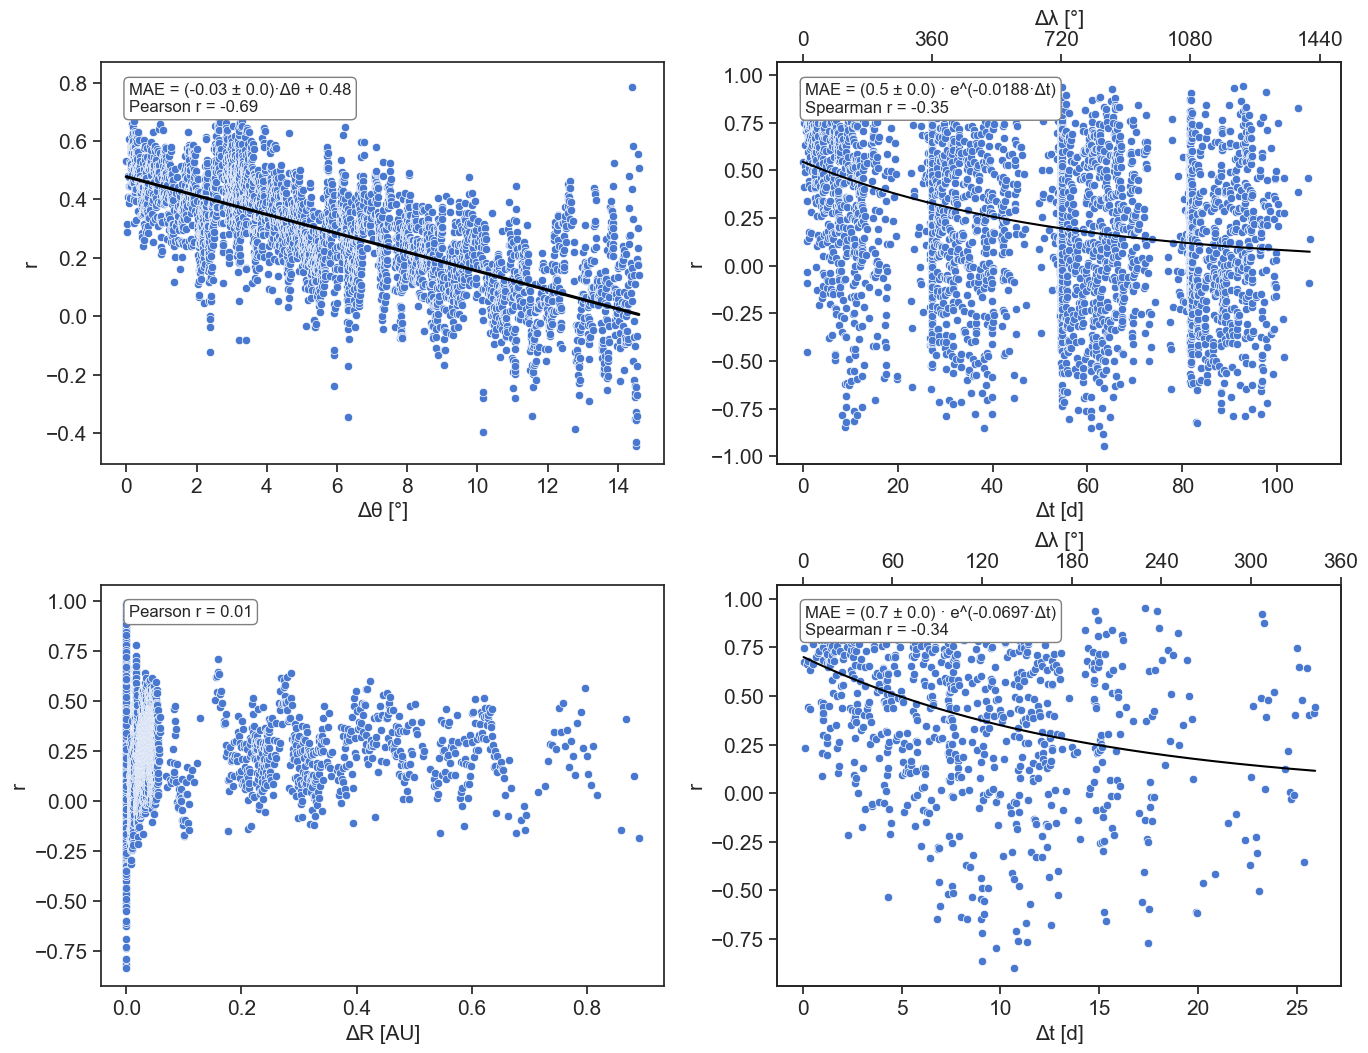

In [17]:
# COR INSTEAD OF MAE

import pandas as pd
import seaborn as sns
from P2D import dataloader
from P2D import P2D_plots
import matplotlib.pyplot as plt
from P2D.utils import spacecraft_ID
import numpy as np
from scipy.stats import linregress, spearmanr
sns.set(
    style="ticks",
    palette="muted",
    rc={
        "axes.labelsize": 15,    # Axis label size
        "xtick.labelsize": 15,   # X-axis tick label size
        "ytick.labelsize": 15,   # Y-axis tick label size
        "font.size": 13,         # Overall font size
        "figure.dpi": 100,        # Dots per inch for figure quality
        "legend.fontsize": 15 # Size of legend
    }
)


# MAVEN

# spacecraft_to_compare = 'MAVEN'

# res1 = pd.read_parquet('model_results_maven_2hsmoothed_inelastic_100dwindow_part1.parquet')
# res2 = pd.read_parquet('model_results_maven_2hsmoothed_inelastic_100dwindow_part2.parquet')
# res3 = pd.read_parquet('model_results_maven_2hsmoothed_inelastic_100dwindow_part3.parquet')

# res = pd.concat([res1, res2, res3]).drop_duplicates(keep='first')

# OMNI

spacecraft_to_compare = 'OMNI'

res1 = pd.read_parquet('model_results_omni_2hsmoothed_inelastic_100dwindow_part1.parquet')
res2 = pd.read_parquet('model_results_omni_2hsmoothed_inelastic_100dwindow_part2.parquet')
res3 = pd.read_parquet('model_results_omni_2hsmoothed_inelastic_100dwindow_part3.parquet')
res4 = pd.read_parquet('model_results_omni_2hsmoothed_inelastic_100dwindow_part4.parquet')
res5 = pd.read_parquet('model_results_omni_2hsmoothed_inelastic_100dwindow_part5.parquet')

res = pd.concat([res1, res2, res3, res4, res5]).drop_duplicates(keep='first')

# MAVEN 2

# spacecraft_to_compare = 'MAVEN'

# res1 = pd.read_parquet('model_cutouts/model_results_maven_2h_smoothed_inelastic_100dwindow_part1.parquet')
# res2 = pd.read_parquet('model_cutouts/model_results_maven_2h_smoothed_inelastic_100dwindow_part2.parquet')
# res3 = pd.read_parquet('model_cutouts/model_results_maven_2h_smoothed_inelastic_100dwindow_part3.parquet')
# res4 = pd.read_parquet('model_cutouts/model_results_maven_2h_smoothed_inelastic_100dwindow_part4.parquet')
# res5 = pd.read_parquet('model_cutouts/model_results_maven_2h_smoothed_inelastic_100dwindow_part5.parquet')
# res6 = pd.read_parquet('model_cutouts/model_results_maven_2h_smoothed_inelastic_100dwindow_part6.parquet')
# res7 = pd.read_parquet('model_cutouts/model_results_maven_2h_smoothed_inelastic_100dwindow_part7.parquet')

# res = pd.concat([res1, res2, res3, res4, res5, res6, res7]).drop_duplicates(keep='first')



time = [res.index[0], res.index[-1]]

omni = dataloader.load(spacecraft=spacecraft_to_compare, timerange=time)
omni = omni[~omni.index.duplicated(keep='first')]
omni = omni.rolling('1d').mean()

remove_cmes=True
if remove_cmes:
    cmes = pd.read_excel('HELIO4CAST_ICMECAT_v23 (1).xlsx')

    spacecraft = ['Wind', 'STEREO-A', 'SolarOrbiter', 'PSP']
    my_spacecraft = ['OMNI', 'STEREO-A', 'SolO', 'PSP']

    for i, sc in enumerate(spacecraft):
        print(sc, ' => ', my_spacecraft[i])
        start_times = pd.to_datetime(cmes.loc[cmes['sc_insitu']==sc]['icme_start_time']).reset_index()['icme_start_time'] - pd.Timedelta(value='6h')
        end_times = pd.to_datetime(cmes.loc[cmes['sc_insitu']==sc]['mo_end_time']).reset_index()['mo_end_time'] + pd.Timedelta(value='6h')

        mask = res['Spacecraft_ID']==spacecraft_ID(my_spacecraft[i], ID_number=True)

        for j in range(len(start_times)):
            
            start = start_times[j].round("h").tz_localize(None)
            end = end_times[j].round("h").tz_localize(None)

            time_mask = (mask.index < end) & (mask.index > start)


            print(start, end, time_mask.sum())
            res[time_mask] = np.nan


#Times
#res['Time'] = res.index
res['Radial_travel_time'] = (res['Time'] - res['Start_time_of_parcel']).dt.total_seconds()/3600/24
res['Persistence_time'] = (res.index - res['Time']).dt.total_seconds()/3600/24
res['Total_time_difference'] = (res.index - res['Start_time_of_parcel']).dt.total_seconds()/3600/24
res['R_difference'] = (res['R'] - res['Start_R_of_parcel'])
# mask = ((res['Spacecraft_ID'] == spacecraft_ID(spacecraft_to_compare, ID_number=True))
#          | (res['Persistence_time'] < 5))
# omni = res[mask]
# omni = omni[~omni.index.duplicated(keep='first')]
#Lat
res['LAT_difference'] = abs(res['LAT'] - res.index.map(omni['LAT']))


########################################################################################

mask = ((res['Spacecraft_ID'] != spacecraft_ID(spacecraft_to_compare, ID_number=True))
         | (res['Persistence_time'] > 20))
res = res[mask]

mask = ((res['Persistence_time'] < 120))
res = res[mask]

# mask = ((res['Persistence_time'] > 20))
# res = res[mask]

########################################################################################



res['V_Measured'] = res.index.map(omni['V'])

res = res.reset_index(drop=True)

points_per_bin = 100  # Number of data points per bin

fig, ax = plt.subplots(2, 2, figsize=(16, 12))

y='R_difference'
    
# Sort the DataFrame by the binning variable
sorted_res = res.sort_values(by=y).reset_index(drop=True)

# Calculate the number of bins based on total data and desired bin size
total_points = len(sorted_res)
bins = total_points // points_per_bin

# Initialize the metric array
metric = np.full(bins, np.nan)
errors = np.full(bins, np.nan)
bin_centers = np.full(bins, np.nan)

for j in range(bins):
    start_idx = j * points_per_bin
    end_idx = (j + 1) * points_per_bin
    subset = sorted_res.iloc[start_idx:end_idx]

    if len(subset) >= 10:
        x_data = subset['V'].to_numpy()
        y_data = subset['V_Measured'].to_numpy()
        valid = ~np.isnan(x_data) & ~np.isnan(y_data)

        if np.sum(valid) >= 100:
            slope, intercept, r_value, p_value, std_err = linregress(
                x_data[valid], y_data[valid])
            mae = abs(x_data[valid] - y_data[valid]).mean()
            metric[j] = r_value
            mae_values = []

            for _ in range(20):
                # Pick random subset indices from valid data
                valid_indices = np.where(valid)[0]
                random_indices = np.random.choice(valid_indices, size=300, replace=True)

                # Calculate MAE for this subset
                slope, intercept, r_value, p_value, std_err = linregress(
                    x_data[random_indices], y_data[random_indices])
                mae = np.abs(x_data[random_indices] - y_data[random_indices]).mean()
                mae_values.append(r_value)

            mae_values = np.array(mae_values)

            # Calculate percentiles
            p5 = np.percentile(mae_values, 5)
            p95 = np.percentile(mae_values, 95)

            difference = p95 - p5

            errors[j] = difference/2
            # Calculate the bin center for plotting
            bin_centers[j] = subset[y].median()


from scipy.optimize import curve_fit

# Define the model function
def model_func(x, a, b):
    return a * np.log(b * x) 

# Filter valid data (no NaNs and valid bin centers)
mask = (~np.isnan(bin_centers)) & (~np.isnan(metric))
x_data = bin_centers[mask]
y_data = metric[mask]


# Perform linear regression
x_data = bin_centers#.to_numpy()
y_data = metric#.to_numpy()
mask = ~np.isnan(x_data) & ~np.isnan(y_data)
slope, intercept, r_value, p_value, std_err = linregress(x_data[mask], y_data[mask])

# Create regression equation string
equation = f"Pearson r = {r_value:.2f}"

# Add to plot
plt.text(
    0.05, 0.95,  # Position in axes coordinates
    equation,
    transform=ax[1, 0].transAxes,
    fontsize=12,
    verticalalignment='top',
    bbox=dict(boxstyle="round,pad=0.3", edgecolor='gray', facecolor='white')
)

# Plot the data and fitted curve
sns.scatterplot(x=x_data, y=y_data, ax=ax[1,0])
#ax[1,0].errorbar(bin_centers, metric, yerr=[errors[mask], errors[mask]], fmt='none', ecolor='black', capsize=3, elinewidth=0.5, alpha=0.5)

# Labels and formatting
ax[1,0].set_xlabel('ΔR [AU]')
ax[1,0].set_ylabel('r')
#plt.legend()


#########################################################################

y='Persistence_time'

   
# Sort the DataFrame by the binning variable
sorted_res = res.sort_values(by=y).reset_index(drop=True)

# Calculate the number of bins based on total data and desired bin size
total_points = len(sorted_res)
bins = total_points // points_per_bin

# Initialize the metric array
metric = np.full(bins, np.nan)
errors = np.full(bins, np.nan)
bin_centers = np.full(bins, np.nan)

for j in range(bins):
    start_idx = j * points_per_bin
    end_idx = (j + 1) * points_per_bin
    subset = sorted_res.iloc[start_idx:end_idx]

    if len(subset) >= 10:
        x_data = subset['V'].to_numpy()
        y_data = subset['V_Measured'].to_numpy()
        valid = ~np.isnan(x_data) & ~np.isnan(y_data)

        if np.sum(valid) >= 100:
            slope, intercept, r_value, p_value, std_err = linregress(
                x_data[valid], y_data[valid])
            mae = abs(x_data[valid] - y_data[valid]).mean()
            metric[j] = r_value
            mae_values = []

            for _ in range(20):
                # Pick random subset indices from valid data
                valid_indices = np.where(valid)[0]
                random_indices = np.random.choice(valid_indices, size=300, replace=True)

                # Calculate MAE for this subset
                slope, intercept, r_value, p_value, std_err = linregress(
                    x_data[random_indices], y_data[random_indices])
                mae = np.abs(x_data[random_indices] - y_data[random_indices]).mean()
                mae_values.append(r_value)

            mae_values = np.array(mae_values)

            # Calculate percentiles
            p5 = np.percentile(mae_values, 5)
            p95 = np.percentile(mae_values, 95)

            difference = p95 - p5

            errors[j] = difference/2
            # Calculate the bin center for plotting
            bin_centers[j] = subset[y].median()


# Define the model function
def model_func(x, a, b):
    return a * np.exp(-b * x)
    #return a * np.log(b * x) 

# Filter valid data (no NaNs and valid bin centers)
mask = (~np.isnan(bin_centers)) & (~np.isnan(metric))
x_data = bin_centers[mask]
y_data = metric[mask]
print(f'LARGE LOG TIMES: {x_data[0]},{x_data[-1]}')
# Fit the curve
try:
    popt, pcov = curve_fit(model_func, x_data, y_data, p0=(1, 5))  # p0 is initial guess
    a_fit, b_fit = popt

        
    perr = np.sqrt(np.diag(pcov)) 
    a_err, b_err = perr

    #print(f"a = {a_fit:.3f} ± {a_err:.3f}")
    #print(f"b = {b_fit:.3f} ± {b_err:.3f}")
    
except RuntimeError:
    print("Curve fitting failed.")
    a_fit, b_fit = np.nan, np.nan
# Compute Spearman correlation
spearman_corr, spearman_p = spearmanr(x_data, y_data)

# Generate fitted curve
x_fit = np.linspace(x_data.min(), x_data.max(), 200)
y_fit = model_func(x_fit, a_fit, b_fit)

# Plot the data and fitted curve
sns.scatterplot(x=x_data, y=y_data, ax=ax[0,1])
#ax[0,1].errorbar(x_data, y_data, yerr=[errors[mask], errors[mask]], fmt='none', ecolor='black', capsize=3, elinewidth=0.5, alpha=0.5)
ax[0,1].plot(x_fit, y_fit, color='black', label='Fit: $y = a /cdot e^{bx}$')

# Display the fitted equation
#equation = f"MAE = ({a_fit:.1f} ± {a_err:.1f}) · ln({b_fit:.1f}·Δt)\nSpearman r = {spearman_corr:.2f}"
equation = f"MAE = ({a_fit:.1f} ± {a_err:.1f}) · e^({-b_fit:.4f}·Δt)\nSpearman r = {spearman_corr:.2f}"
ax[0,1].text(
    0.05, 0.95,
    equation,
    transform=ax[0,1].transAxes,
    fontsize=12,
    verticalalignment='top',
    bbox=dict(boxstyle="round,pad=0.3", edgecolor='gray', facecolor='white')
)

# Labels and formatting
# Labels and formatting
ax[0,1].set_xlabel('Δt [d]')
ax[0,1].set_ylabel('r')
span = 108
ax[0,1].set_xlim(span*(-0.05), span*(1.05))

ax01 = ax[0,1].twiny()


span = 1440*108/27.24/4
ax01.set_xlim(span*(-0.05), span*(1.05))
ax01.set_xlabel('Δλ [°]')
ax01.set_xticks(np.arange(0,1441, 360))
#plt.legend()
 
#plt.legend()



#########################################################################

y='LAT_difference'

   
# Sort the DataFrame by the binning variable
sorted_res = res.sort_values(by=y).reset_index(drop=True)

# Calculate the number of bins based on total data and desired bin size
total_points = len(sorted_res)
bins = total_points // points_per_bin

# Initialize the metric array
metric = np.full(bins, np.nan)
errors = np.full(bins, np.nan)
bin_centers = np.full(bins, np.nan)

for j in range(bins):
    start_idx = j * points_per_bin
    end_idx = (j + 1) * points_per_bin
    subset = sorted_res.iloc[start_idx:end_idx]

    if len(subset) >= 10:
        x_data = subset['V'].to_numpy()
        y_data = subset['V_Measured'].to_numpy()
        valid = ~np.isnan(x_data) & ~np.isnan(y_data)

        if np.sum(valid) >= 100:
            slope, intercept, r_value, p_value, std_err = linregress(
                x_data[valid], y_data[valid])
            mae = abs(x_data[valid] - y_data[valid]).mean()
            metric[j] = r_value
            mae_values = []

            for _ in range(20):
                # Pick random subset indices from valid data
                valid_indices = np.where(valid)[0]
                random_indices = np.random.choice(valid_indices, size=300, replace=True)

                # Calculate MAE for this subset
                slope, intercept, r_value, p_value, std_err = linregress(
                    x_data[random_indices], y_data[random_indices])
                mae = np.abs(x_data[random_indices] - y_data[random_indices]).mean()
                mae_values.append(r_value)

            mae_values = np.array(mae_values)

            # Calculate percentiles
            p5 = np.percentile(mae_values, 5)
            p95 = np.percentile(mae_values, 95)

            difference = p95 - p5

            errors[j] = difference/2
            # Calculate the bin center for plotting
            bin_centers[j] = subset[y].median()



# Plot with one global regression line
sns.regplot(
    x=bin_centers,
    y=metric,
    scatter=False,
    ci=None,       # Optional: remove confidence interval
    line_kws={'color': 'black'},
    ax=ax[0,0]  # Optional: color of regression line
)

# Perform linear regression
x_data = bin_centers#.to_numpy()
y_data = metric#.to_numpy()
mask = ~np.isnan(x_data) & ~np.isnan(y_data) & (y_data<120)

print(f'LATS: {x_data[0]},{x_data[-1]}')

slope, intercept, r_value, p_value, std_err = linregress(x_data[mask], y_data[mask])

# Create regression equation string
equation = f"MAE = ({slope:.2f} ± {std_err:.1f})·Δθ + {intercept:.2f}\nPearson r = {r_value:.2f}"
# Add to plot
ax[0,0].text(
    0.05, 0.95,  # Position in axes coordinates
    equation,
    transform=ax[0,0].transAxes,
    fontsize=12,
    verticalalignment='top',
    bbox=dict(boxstyle="round,pad=0.3", edgecolor='gray', facecolor='white')
)

# Plot the data and fitted curve
sns.scatterplot(x=x_data[mask], y=y_data[mask], ax=ax[0,0])
#ax[0,0].errorbar(x_data[mask], y_data[mask], yerr=[errors[mask], errors[mask]], fmt='none', ecolor='black', capsize=3, elinewidth=0.5, alpha=0.5)

# Labels and formatting
ax[0,0].set_xlabel('Δθ [°]')
ax[0,0].set_ylabel('r')



###########################################################

y='Persistence_time'

mask = ((res['Persistence_time'] < 26))
res = res[mask]

#points_per_bin = 1000

# Sort the DataFrame by the binning variable
sorted_res = res.sort_values(by=y).reset_index(drop=True)

# Calculate the number of bins based on total data and desired bin size
total_points = len(sorted_res)
bins = total_points // points_per_bin

# Initialize the metric array
metric = np.full(bins, np.nan)
errors = np.full(bins, np.nan)
bin_centers = np.full(bins, np.nan)

for j in range(bins):
    start_idx = j * points_per_bin
    end_idx = (j + 1) * points_per_bin
    subset = sorted_res.iloc[start_idx:end_idx]

    if len(subset) >= 10:
        x_data = subset['V'].to_numpy()
        y_data = subset['V_Measured'].to_numpy()
        valid = ~np.isnan(x_data) & ~np.isnan(y_data)

        if np.sum(valid) >= 10:
            slope, intercept, r_value, p_value, std_err = linregress(
                x_data[valid], y_data[valid])
            mae = abs(x_data[valid] - y_data[valid]).mean()
            metric[j] = r_value
            mae_values = []

            for _ in range(20):
                # Pick random subset indices from valid data
                valid_indices = np.where(valid)[0]
                random_indices = np.random.choice(valid_indices, size=300, replace=True)

                # Calculate MAE for this subset
                slope, intercept, r_value, p_value, std_err = linregress(
                    x_data[random_indices], y_data[random_indices])
                mae = np.abs(x_data[random_indices] - y_data[random_indices]).mean()
                mae_values.append(r_value)

            mae_values = np.array(mae_values)

            # Calculate percentiles
            p5 = np.percentile(mae_values, 5)
            p95 = np.percentile(mae_values, 95)

            difference = p95 - p5

            errors[j] = difference/2
            # Calculate the bin center for plotting
            bin_centers[j] = subset[y].median()


# Define the model function
def model_func(x, a, b):
    #return a * np.log(b * x) 
    return a * np.exp(-b * x)

# Filter valid data (no NaNs and valid bin centers)
mask = (~np.isnan(bin_centers)) & (~np.isnan(metric))& (bin_centers > 0)
x_data = bin_centers[mask]
y_data = metric[mask]

print(f'SMALL LOG TIMES: {x_data[0]},{x_data[-1]}')
#x_data = x_data/x_data.max()*360
# Fit the curve
try:
    popt, pcov = curve_fit(model_func, x_data, y_data, p0=(1, 5))  # p0 is initial guess
    a_fit, b_fit = popt

    perr = np.sqrt(np.diag(pcov)) 
    a_err, b_err = perr

except RuntimeError:
    print("Curve fitting failed.")
    a_fit, b_fit = np.nan, np.nan

# Compute Spearman correlation
spearman_corr, spearman_p = spearmanr(x_data, y_data)

# Generate fitted curve
x_fit = np.linspace(x_data.min(), x_data.max(), 200)
y_fit = model_func(x_fit, a_fit, b_fit)

# Plot the data and fitted curve
sns.scatterplot(x=x_data, y=y_data, ax=ax[1,1])
#ax[1,1].errorbar(x_data, y_data, yerr=[errors[mask], errors[mask]], fmt='none', ecolor='black', capsize=3, elinewidth=0.5, alpha=0.5)
ax[1,1].plot(x_fit, y_fit, color='black', label='Fit: $y = a /cdot e^{bx}$')

# Display the fitted equation
equation = f"MAE = ({a_fit:.1f} ± {a_err:.1f}) · ln({b_fit:.1f}· Δt)\nSpearman r = {spearman_corr:.2f}"
equation = f"MAE = ({a_fit:.1f} ± {a_err:.1f}) · e^({-b_fit:.4f}·Δt)\nSpearman r = {spearman_corr:.2f}"
ax[1,1].text(
    0.05, 0.95,
    equation,
    transform=ax[1,1].transAxes,
    fontsize=12,
    verticalalignment='top',
    bbox=dict(boxstyle="round,pad=0.3", edgecolor='gray', facecolor='white')
)

# Labels and formatting
ax[1,1].set_xlabel('Δt [d]')
ax[1,1].set_ylabel('r')
span = x_data.max()
ax[1,1].set_xlim(span*(-0.05), span*(1.05))

ax11 = ax[1,1].twiny()


span = 360*x_data.max()/27.24
ax11.set_xlim(span*(-0.05), span*(1.05))
ax11.set_xlabel('Δλ [°]')
ax11.set_xticks(np.arange(0,361, 60))
#plt.legend()








plt.subplots_adjust(hspace=0.3)


#plt.tight_layout()
#plt.savefig('C:/Users/14milosi/Desktop/Paper2/Outline/Correlations.pdf')
plt.show()

[Info] Attempting download from https://raw.githubusercontent.com/danielmilosic/DRaD/master/reduced_data/omni/omni_data2024-09.parquet
[Warning] Skipping 2024-09: GitHub file not available (404)
Wind  =>  OMNI
2024-12-16 22:00:00 2024-12-17 20:00:00 0
2024-12-07 17:00:00 2024-12-09 00:00:00 0
2024-11-28 20:00:00 2024-11-29 23:00:00 0
2024-11-13 21:00:00 2024-11-14 22:00:00 0
2024-11-09 16:00:00 2024-11-10 17:00:00 0
2024-11-08 16:00:00 2024-11-09 18:00:00 0
2024-11-08 04:00:00 2024-11-09 01:00:00 0
2024-10-26 10:00:00 2024-10-27 15:00:00 55
2024-10-10 09:00:00 2024-10-11 16:00:00 37
2024-10-07 16:00:00 2024-10-08 15:00:00 22
2024-10-07 06:00:00 2024-10-08 02:00:00 19
2024-10-06 01:00:00 2024-10-07 07:00:00 29
2024-09-16 17:00:00 2024-09-17 18:00:00 23
2024-09-12 02:00:00 2024-09-13 06:00:00 27
2024-09-11 21:00:00 2024-09-12 14:00:00 16
2024-08-31 06:00:00 2024-09-01 15:00:00 117
2024-08-27 02:00:00 2024-08-29 22:00:00 253
2024-08-17 08:00:00 2024-08-18 15:00:00 94
2024-08-10 06:00:00 2

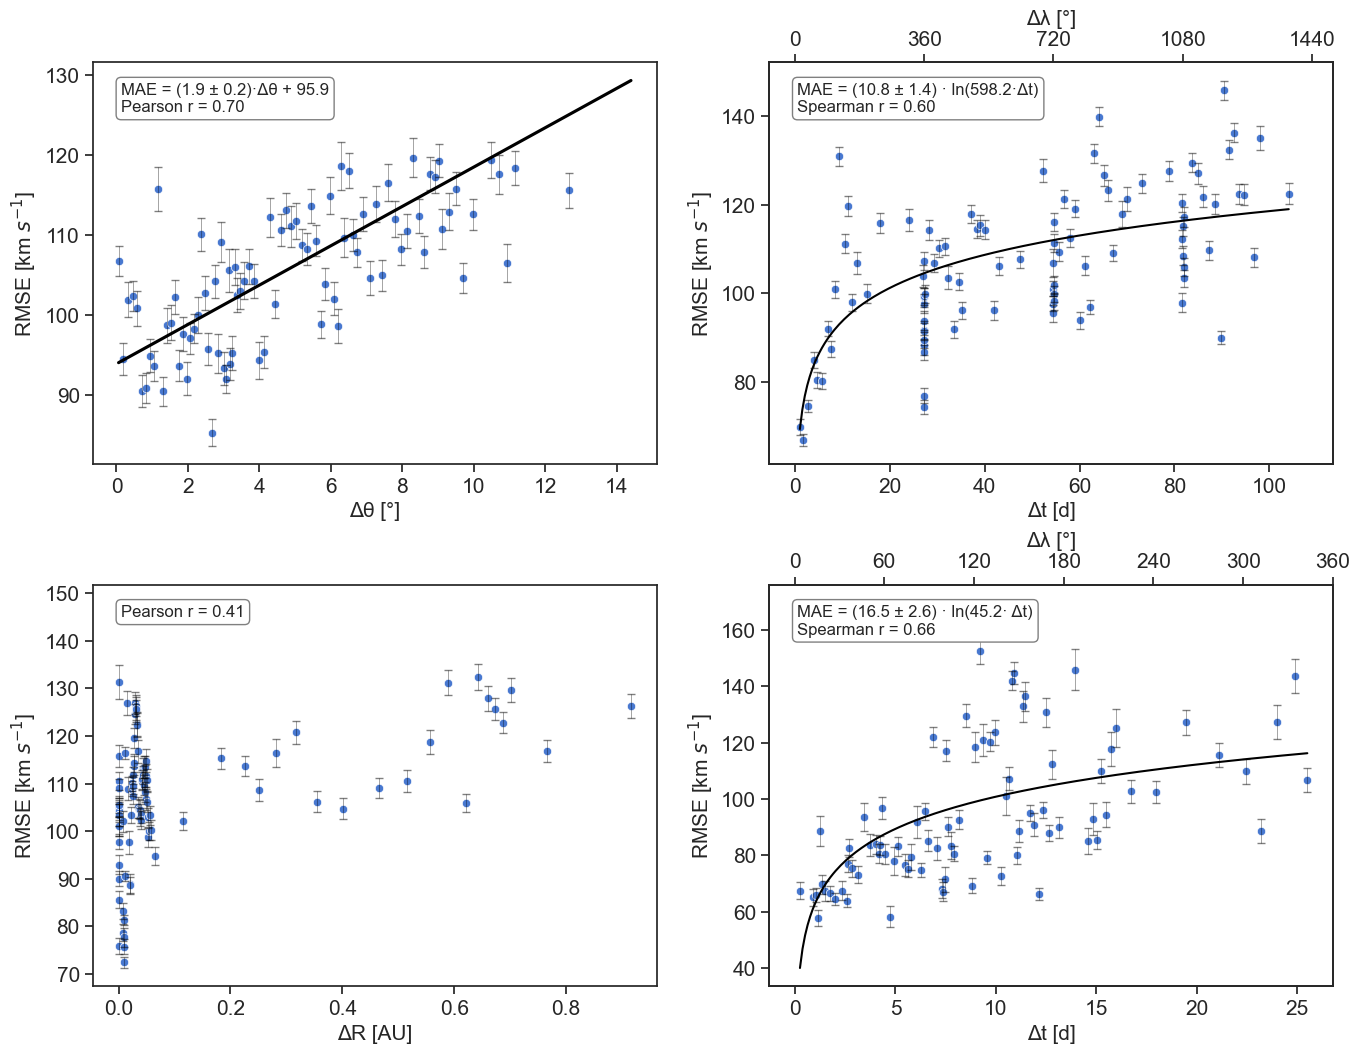

In [1]:
# RMSE INSTEAD OF MAE

import pandas as pd
import seaborn as sns
from P2D import dataloader
from P2D import P2D_plots
import matplotlib.pyplot as plt
from P2D.utils import spacecraft_ID
import numpy as np
from scipy.stats import linregress, spearmanr
sns.set(
    style="ticks",
    palette="muted",
    rc={
        "axes.labelsize": 15,    # Axis label size
        "xtick.labelsize": 15,   # X-axis tick label size
        "ytick.labelsize": 15,   # Y-axis tick label size
        "font.size": 13,         # Overall font size
        "figure.dpi": 100,        # Dots per inch for figure quality
        "legend.fontsize": 15 # Size of legend
    }
)


# MAVEN

# spacecraft_to_compare = 'MAVEN'

# res1 = pd.read_parquet('model_results_maven_2hsmoothed_inelastic_100dwindow_part1.parquet')
# res2 = pd.read_parquet('model_results_maven_2hsmoothed_inelastic_100dwindow_part2.parquet')
# res3 = pd.read_parquet('model_results_maven_2hsmoothed_inelastic_100dwindow_part3.parquet')

# res = pd.concat([res1, res2, res3]).drop_duplicates(keep='first')

# OMNI

spacecraft_to_compare = 'OMNI'

res1 = pd.read_parquet('model_cutouts/model_results_omni_2h_smoothed_inelastic_100dwindow_part1.parquet')
res2 = pd.read_parquet('model_cutouts/model_results_omni_2h_smoothed_inelastic_100dwindow_part2.parquet')
res3 = pd.read_parquet('model_cutouts/model_results_omni_2h_smoothed_inelastic_100dwindow_part3.parquet')
res4 = pd.read_parquet('model_cutouts/model_results_omni_2h_smoothed_inelastic_100dwindow_part4.parquet')
res5 = pd.read_parquet('model_cutouts/model_results_omni_2h_smoothed_inelastic_100dwindow_part5.parquet')
res6 = pd.read_parquet('model_cutouts/model_results_omni_2h_smoothed_inelastic_100dwindow_part6.parquet')
res7 = pd.read_parquet('model_cutouts/model_results_omni_2h_smoothed_inelastic_100dwindow_part7.parquet')


res = pd.concat([res1, res2, res3, res4, res5, res6, res7]).drop_duplicates(keep='first')

# MAVEN 2

# spacecraft_to_compare = 'MAVEN'

# res1 = pd.read_parquet('model_cutouts/model_results_maven_2h_smoothed_inelastic_100dwindow_part1.parquet')
# res2 = pd.read_parquet('model_cutouts/model_results_maven_2h_smoothed_inelastic_100dwindow_part2.parquet')
# res3 = pd.read_parquet('model_cutouts/model_results_maven_2h_smoothed_inelastic_100dwindow_part3.parquet')
# res4 = pd.read_parquet('model_cutouts/model_results_maven_2h_smoothed_inelastic_100dwindow_part4.parquet')
# res5 = pd.read_parquet('model_cutouts/model_results_maven_2h_smoothed_inelastic_100dwindow_part5.parquet')
# res6 = pd.read_parquet('model_cutouts/model_results_maven_2h_smoothed_inelastic_100dwindow_part6.parquet')
# res7 = pd.read_parquet('model_cutouts/model_results_maven_2h_smoothed_inelastic_100dwindow_part7.parquet')

# res = pd.concat([res1, res2, res3, res4, res5, res6, res7]).drop_duplicates(keep='first')



time = [res.index[0], res.index[-1]]

omni = dataloader.load(spacecraft=spacecraft_to_compare, timerange=time)
omni = omni[~omni.index.duplicated(keep='first')]
omni = omni.rolling('1d').mean()

remove_cmes=True
if remove_cmes:
    cmes = pd.read_excel('HELIO4CAST_ICMECAT_v23 (1).xlsx')

    spacecraft = ['Wind', 'STEREO-A', 'SolarOrbiter', 'PSP']
    my_spacecraft = ['OMNI', 'STEREO-A', 'SolO', 'PSP']

    for i, sc in enumerate(spacecraft):
        print(sc, ' => ', my_spacecraft[i])
        start_times = pd.to_datetime(cmes.loc[cmes['sc_insitu']==sc]['icme_start_time']).reset_index()['icme_start_time'] - pd.Timedelta(value='6h')
        end_times = pd.to_datetime(cmes.loc[cmes['sc_insitu']==sc]['mo_end_time']).reset_index()['mo_end_time'] + pd.Timedelta(value='6h')

        mask = res['Spacecraft_ID']==spacecraft_ID(my_spacecraft[i], ID_number=True)

        for j in range(len(start_times)):
            
            start = start_times[j].round("h").tz_localize(None)
            end = end_times[j].round("h").tz_localize(None)

            time_mask = (mask.index < end) & (mask.index > start)


            print(start, end, time_mask.sum())
            res[time_mask] = np.nan


#Times
#res['Time'] = res.index
res['Radial_travel_time'] = (res['Time'] - res['Start_time_of_parcel']).dt.total_seconds()/3600/24
res['Persistence_time'] = (res.index - res['Time']).dt.total_seconds()/3600/24
res['Total_time_difference'] = (res.index - res['Start_time_of_parcel']).dt.total_seconds()/3600/24
res['R_difference'] = (res['R'] - res['Start_R_of_parcel'])
# mask = ((res['Spacecraft_ID'] == spacecraft_ID(spacecraft_to_compare, ID_number=True))
#          | (res['Persistence_time'] < 5))
# omni = res[mask]
# omni = omni[~omni.index.duplicated(keep='first')]
#Lat
res['LAT_difference'] = abs(res['LAT'] - res.index.map(omni['LAT']))


########################################################################################

mask = ((res['Spacecraft_ID'] != spacecraft_ID(spacecraft_to_compare, ID_number=True))
         | (res['Persistence_time'] > 20))
res = res[mask]

mask = ((res['Persistence_time'] < 120))
res = res[mask]

# mask = ((res['Persistence_time'] > 20))
# res = res[mask]

########################################################################################



res['V_Measured'] = res.index.map(omni['V'])

res = res.reset_index(drop=True)

points_per_bin = 5000  # Number of data points per bin

fig, ax = plt.subplots(2, 2, figsize=(16, 12))

y='R_difference'
    
# Sort the DataFrame by the binning variable
sorted_res = res.sort_values(by=y).reset_index(drop=True)

# Calculate the number of bins based on total data and desired bin size
total_points = len(sorted_res)
bins = total_points // points_per_bin

# Initialize the metric array
metric = np.full(bins, np.nan)
errors = np.full(bins, np.nan)
bin_centers = np.full(bins, np.nan)

for j in range(bins):
    start_idx = j * points_per_bin
    end_idx = (j + 1) * points_per_bin
    subset = sorted_res.iloc[start_idx:end_idx]

    if len(subset) >= 10:
        x_data = subset['V'].to_numpy()
        y_data = subset['V_Measured'].to_numpy()
        valid = ~np.isnan(x_data) & ~np.isnan(y_data)

        if np.sum(valid) >= 100:
            slope, intercept, r_value, p_value, std_err = linregress(
                x_data[valid], y_data[valid])
            mae = abs(x_data[valid] - y_data[valid]).mean()
            rmse = np.sqrt(np.sum((x_data[valid] - y_data[valid])**2)/np.sum(valid))
            metric[j] = rmse
            mae_values = []

            for _ in range(2000):
                # Pick random subset indices from valid data
                valid_indices = np.where(valid)[0]
                random_indices = np.random.choice(valid_indices, size=300, replace=True)

                # Calculate MAE for this subset
                mae = np.abs(x_data[random_indices] - y_data[random_indices]).mean()
                rmse = np.sqrt(np.sum((x_data[random_indices] - y_data[random_indices])**2)/np.sum(valid))
                mae_values.append(rmse)

            mae_values = np.array(mae_values)

            # Calculate percentiles
            p5 = np.percentile(mae_values, 5)
            p95 = np.percentile(mae_values, 95)

            difference = p95 - p5

            errors[j] = difference/2
            # Calculate the bin center for plotting
            bin_centers[j] = subset[y].median()


from scipy.optimize import curve_fit

# Define the model function
def model_func(x, a, b):
    return a * np.log(b * x) 

# Filter valid data (no NaNs and valid bin centers)
mask = (~np.isnan(bin_centers)) & (~np.isnan(metric))
x_data = bin_centers[mask]
y_data = metric[mask]


# Perform linear regression
x_data = bin_centers#.to_numpy()
y_data = metric#.to_numpy()
mask = ~np.isnan(x_data) & ~np.isnan(y_data)
slope, intercept, r_value, p_value, std_err = linregress(x_data[mask], y_data[mask])

# Create regression equation string
equation = f"Pearson r = {r_value:.2f}"

# Add to plot
plt.text(
    0.05, 0.95,  # Position in axes coordinates
    equation,
    transform=ax[1, 0].transAxes,
    fontsize=12,
    verticalalignment='top',
    bbox=dict(boxstyle="round,pad=0.3", edgecolor='gray', facecolor='white')
)

# Plot the data and fitted curve
sns.scatterplot(x=x_data, y=y_data, ax=ax[1,0])
ax[1,0].errorbar(bin_centers, metric, yerr=[errors[mask], errors[mask]], fmt='none', ecolor='black', capsize=3, elinewidth=0.5, alpha=0.5)

# Labels and formatting
ax[1,0].set_xlabel('ΔR [AU]')
ax[1,0].set_ylabel(r'RMSE [km $s^{-1}$]')
#plt.legend()


#########################################################################

y='Persistence_time'

   
# Sort the DataFrame by the binning variable
sorted_res = res.sort_values(by=y).reset_index(drop=True)

# Calculate the number of bins based on total data and desired bin size
total_points = len(sorted_res)
bins = total_points // points_per_bin

# Initialize the metric array
metric = np.full(bins, np.nan)
errors = np.full(bins, np.nan)
bin_centers = np.full(bins, np.nan)

for j in range(bins):
    start_idx = j * points_per_bin
    end_idx = (j + 1) * points_per_bin
    subset = sorted_res.iloc[start_idx:end_idx]

    if len(subset) >= 10:
        x_data = subset['V'].to_numpy()
        y_data = subset['V_Measured'].to_numpy()
        valid = ~np.isnan(x_data) & ~np.isnan(y_data)

        if np.sum(valid) >= 100:
            slope, intercept, r_value, p_value, std_err = linregress(
                x_data[valid], y_data[valid])
            mae = abs(x_data[valid] - y_data[valid]).mean()
            rmse = np.sqrt(np.sum((x_data[valid] - y_data[valid])**2)/np.sum(valid))
            metric[j] = rmse
            mae_values = []

            for _ in range(2000):
                # Pick random subset indices from valid data
                valid_indices = np.where(valid)[0]
                random_indices = np.random.choice(valid_indices, size=300, replace=True)

                # Calculate MAE for this subset
                mae = np.abs(x_data[random_indices] - y_data[random_indices]).mean()
                rmse = np.sqrt(np.sum((x_data[random_indices] - y_data[random_indices])**2)/np.sum(valid))
                mae_values.append(rmse)

            mae_values = np.array(mae_values)

            # Calculate percentiles
            p5 = np.percentile(mae_values, 5)
            p95 = np.percentile(mae_values, 95)

            difference = p95 - p5

            errors[j] = difference/2
            # Calculate the bin center for plotting
            bin_centers[j] = subset[y].median()


# Define the model function
def model_func(x, a, b):
    #return 160 - a * np.exp(b * x)
    return a * np.log(b * x) 

# Filter valid data (no NaNs and valid bin centers)
mask = (~np.isnan(bin_centers)) & (~np.isnan(metric))
x_data = bin_centers[mask]
y_data = metric[mask]
print(f'LARGE LOG TIMES: {x_data[0]},{x_data[-1]}')
# Fit the curve
try:
    popt, pcov = curve_fit(model_func, x_data, y_data, p0=(10, 50))  # p0 is initial guess
    a_fit, b_fit = popt

        
    perr = np.sqrt(np.diag(pcov)) 
    a_err, b_err = perr

    #print(f"a = {a_fit:.3f} ± {a_err:.3f}")
    #print(f"b = {b_fit:.3f} ± {b_err:.3f}")
    
except RuntimeError:
    print("Curve fitting failed.")
    a_fit, b_fit = np.nan, np.nan
# Compute Spearman correlation
spearman_corr, spearman_p = spearmanr(x_data, y_data)

# Generate fitted curve
x_fit = np.linspace(x_data.min(), x_data.max(), 200)
y_fit = model_func(x_fit, a_fit, b_fit)

# Plot the data and fitted curve
sns.scatterplot(x=x_data, y=y_data, ax=ax[0,1])
ax[0,1].errorbar(x_data, y_data, yerr=[errors[mask], errors[mask]], fmt='none', ecolor='black', capsize=3, elinewidth=0.5, alpha=0.5)
ax[0,1].plot(x_fit, y_fit, color='black', label='Fit: $y = a /cdot e^{bx}$')

# Display the fitted equation
equation = f"MAE = ({a_fit:.1f} ± {a_err:.1f}) · ln({b_fit:.1f}·Δt)\nSpearman r = {spearman_corr:.2f}"
#equation = f"MAE = ({a_fit:.1f} ± {a_err:.1f}) · e^({b_fit:.4f}·Δt)\nSpearman r = {spearman_corr:.2f}"
ax[0,1].text(
    0.05, 0.95,
    equation,
    transform=ax[0,1].transAxes,
    fontsize=12,
    verticalalignment='top',
    bbox=dict(boxstyle="round,pad=0.3", edgecolor='gray', facecolor='white')
)

# Labels and formatting
# Labels and formatting
ax[0,1].set_xlabel('Δt [d]')
ax[0,1].set_ylabel(r'RMSE [km $s^{-1}$]')
span = 108
ax[0,1].set_xlim(span*(-0.05), span*(1.05))

ax01 = ax[0,1].twiny()


span = 1440*108/27.24/4
ax01.set_xlim(span*(-0.05), span*(1.05))
ax01.set_xlabel('Δλ [°]')
ax01.set_xticks(np.arange(0,1441, 360))
#plt.legend()
 
#plt.legend()



#########################################################################

y='LAT_difference'

   
# Sort the DataFrame by the binning variable
sorted_res = res.sort_values(by=y).reset_index(drop=True)

# Calculate the number of bins based on total data and desired bin size
total_points = len(sorted_res)
bins = total_points // points_per_bin

# Initialize the metric array
metric = np.full(bins, np.nan)
errors = np.full(bins, np.nan)
bin_centers = np.full(bins, np.nan)

for j in range(bins):
    start_idx = j * points_per_bin
    end_idx = (j + 1) * points_per_bin
    subset = sorted_res.iloc[start_idx:end_idx]

    if len(subset) >= 10:
        x_data = subset['V'].to_numpy()
        y_data = subset['V_Measured'].to_numpy()
        valid = ~np.isnan(x_data) & ~np.isnan(y_data)

        if np.sum(valid) >= 100:
            slope, intercept, r_value, p_value, std_err = linregress(
                x_data[valid], y_data[valid])
            mae = abs(x_data[valid] - y_data[valid]).mean()
            rmse = np.sqrt(np.sum((x_data[valid] - y_data[valid])**2)/np.sum(valid))
            metric[j] = rmse
            mae_values = []

            for _ in range(2000):
                # Pick random subset indices from valid data
                valid_indices = np.where(valid)[0]
                random_indices = np.random.choice(valid_indices, size=300, replace=True)

                # Calculate MAE for this subset
                mae = np.abs(x_data[random_indices] - y_data[random_indices]).mean()
                rmse = np.sqrt(np.sum((x_data[random_indices] - y_data[random_indices])**2)/np.sum(valid))
                mae_values.append(rmse)

            mae_values = np.array(mae_values)

            # Calculate percentiles
            p5 = np.percentile(mae_values, 5)
            p95 = np.percentile(mae_values, 95)

            difference = p95 - p5

            errors[j] = difference/2
            # Calculate the bin center for plotting
            bin_centers[j] = subset[y].median()



# Plot with one global regression line
sns.regplot(
    x=bin_centers,
    y=metric,
    scatter=False,
    ci=None,       # Optional: remove confidence interval
    line_kws={'color': 'black'},
    ax=ax[0,0]  # Optional: color of regression line
)

# Perform linear regression
x_data = bin_centers#.to_numpy()
y_data = metric#.to_numpy()
mask = ~np.isnan(x_data) & ~np.isnan(y_data) & (y_data<120)

print(f'LATS: {x_data[0]},{x_data[-1]}')

slope, intercept, r_value, p_value, std_err = linregress(x_data[mask], y_data[mask])

# Create regression equation string
equation = f"MAE = ({slope:.1f} ± {std_err:.1f})·Δθ + {intercept:.1f}\nPearson r = {r_value:.2f}"
# Add to plot
ax[0,0].text(
    0.05, 0.95,  # Position in axes coordinates
    equation,
    transform=ax[0,0].transAxes,
    fontsize=12,
    verticalalignment='top',
    bbox=dict(boxstyle="round,pad=0.3", edgecolor='gray', facecolor='white')
)

# Plot the data and fitted curve
sns.scatterplot(x=x_data[mask], y=y_data[mask], ax=ax[0,0])
ax[0,0].errorbar(x_data[mask], y_data[mask], yerr=[errors[mask], errors[mask]], fmt='none', ecolor='black', capsize=3, elinewidth=0.5, alpha=0.5)

# Labels and formatting
ax[0,0].set_xlabel('Δθ [°]')
ax[0,0].set_ylabel(r'RMSE [km $s^{-1}$]')



###########################################################

y='Persistence_time'

mask = ((res['Persistence_time'] < 26))
res = res[mask]

points_per_bin = 1000

# Sort the DataFrame by the binning variable
sorted_res = res.sort_values(by=y).reset_index(drop=True)

# Calculate the number of bins based on total data and desired bin size
total_points = len(sorted_res)
bins = total_points // points_per_bin

# Initialize the metric array
metric = np.full(bins, np.nan)
errors = np.full(bins, np.nan)
bin_centers = np.full(bins, np.nan)

for j in range(bins):
    start_idx = j * points_per_bin
    end_idx = (j + 1) * points_per_bin
    subset = sorted_res.iloc[start_idx:end_idx]

    if len(subset) >= 10:
        x_data = subset['V'].to_numpy()
        y_data = subset['V_Measured'].to_numpy()
        valid = ~np.isnan(x_data) & ~np.isnan(y_data)

        if np.sum(valid) >= 10:
            slope, intercept, r_value, p_value, std_err = linregress(
                x_data[valid], y_data[valid])
            mae = abs(x_data[valid] - y_data[valid]).mean()
            rmse = np.sqrt(np.sum((x_data[valid] - y_data[valid])**2)/np.sum(valid))
            metric[j] = rmse
            mae_values = []

            for _ in range(2000):
                # Pick random subset indices from valid data
                valid_indices = np.where(valid)[0]
                random_indices = np.random.choice(valid_indices, size=300, replace=True)

                # Calculate MAE for this subset
                mae = np.abs(x_data[random_indices] - y_data[random_indices]).mean()
                rmse = np.sqrt(np.sum((x_data[random_indices] - y_data[random_indices])**2)/np.sum(valid))
                mae_values.append(rmse)

            mae_values = np.array(mae_values)

            # Calculate percentiles
            p5 = np.percentile(mae_values, 5)
            p95 = np.percentile(mae_values, 95)

            difference = p95 - p5

            errors[j] = difference/2
            # Calculate the bin center for plotting
            bin_centers[j] = subset[y].median()


# Define the model function
def model_func(x, a, b):
    return a * np.log(b * x) 

# Filter valid data (no NaNs and valid bin centers)
mask = (~np.isnan(bin_centers)) & (~np.isnan(metric))& (bin_centers > 0)
x_data = bin_centers[mask]
y_data = metric[mask]

print(f'SMALL LOG TIMES: {x_data[0]},{x_data[-1]}')
#x_data = x_data/x_data.max()*360
# Fit the curve
try:
    popt, pcov = curve_fit(model_func, x_data, y_data, p0=(10, 50))  # p0 is initial guess
    a_fit, b_fit = popt

    perr = np.sqrt(np.diag(pcov)) 
    a_err, b_err = perr

except RuntimeError:
    print("Curve fitting failed.")
    a_fit, b_fit = np.nan, np.nan

# Compute Spearman correlation
spearman_corr, spearman_p = spearmanr(x_data, y_data)

# Generate fitted curve
x_fit = np.linspace(x_data.min(), x_data.max(), 200)
y_fit = model_func(x_fit, a_fit, b_fit)

# Plot the data and fitted curve
sns.scatterplot(x=x_data, y=y_data, ax=ax[1,1])
ax[1,1].errorbar(x_data, y_data, yerr=[errors[mask], errors[mask]], fmt='none', ecolor='black', capsize=3, elinewidth=0.5, alpha=0.5)
ax[1,1].plot(x_fit, y_fit, color='black', label='Fit: $y = a /cdot e^{bx}$')

# Display the fitted equation
equation = f"MAE = ({a_fit:.1f} ± {a_err:.1f}) · ln({b_fit:.1f}· Δt)\nSpearman r = {spearman_corr:.2f}"
ax[1,1].text(
    0.05, 0.95,
    equation,
    transform=ax[1,1].transAxes,
    fontsize=12,
    verticalalignment='top',
    bbox=dict(boxstyle="round,pad=0.3", edgecolor='gray', facecolor='white')
)

# Labels and formatting
ax[1,1].set_xlabel('Δt [d]')
ax[1,1].set_ylabel(r'RMSE [km $s^{-1}$]')
span = x_data.max()
ax[1,1].set_xlim(span*(-0.05), span*(1.05))

ax11 = ax[1,1].twiny()


span = 360*x_data.max()/27.24
ax11.set_xlim(span*(-0.05), span*(1.05))
ax11.set_xlabel('Δλ [°]')
ax11.set_xticks(np.arange(0,361, 60))
#plt.legend()
 
plt.subplots_adjust(hspace=0.3)


#plt.tight_layout()
#plt.savefig('C:/Users/14milosi/Desktop/Paper2/Outline/Correlations.pdf')
plt.show()

[Info] Attempting download from https://raw.githubusercontent.com/danielmilosic/DRaD/master/reduced_data/omni/omni_data2024-09.parquet
[Warning] Skipping 2024-09: GitHub file not available (404)
Wind  =>  OMNI
2024-12-16 22:00:00 2024-12-17 20:00:00 0
2024-12-07 17:00:00 2024-12-09 00:00:00 0
2024-11-28 20:00:00 2024-11-29 23:00:00 0
2024-11-13 21:00:00 2024-11-14 22:00:00 0
2024-11-09 16:00:00 2024-11-10 17:00:00 0
2024-11-08 16:00:00 2024-11-09 18:00:00 0
2024-11-08 04:00:00 2024-11-09 01:00:00 0
2024-10-26 10:00:00 2024-10-27 15:00:00 55
2024-10-10 09:00:00 2024-10-11 16:00:00 37
2024-10-07 16:00:00 2024-10-08 15:00:00 22
2024-10-07 06:00:00 2024-10-08 02:00:00 19
2024-10-06 01:00:00 2024-10-07 07:00:00 29
2024-09-16 17:00:00 2024-09-17 18:00:00 23
2024-09-12 02:00:00 2024-09-13 06:00:00 27
2024-09-11 21:00:00 2024-09-12 14:00:00 16
2024-08-31 06:00:00 2024-09-01 15:00:00 117
2024-08-27 02:00:00 2024-08-29 22:00:00 253
2024-08-17 08:00:00 2024-08-18 15:00:00 94
2024-08-10 06:00:00 2

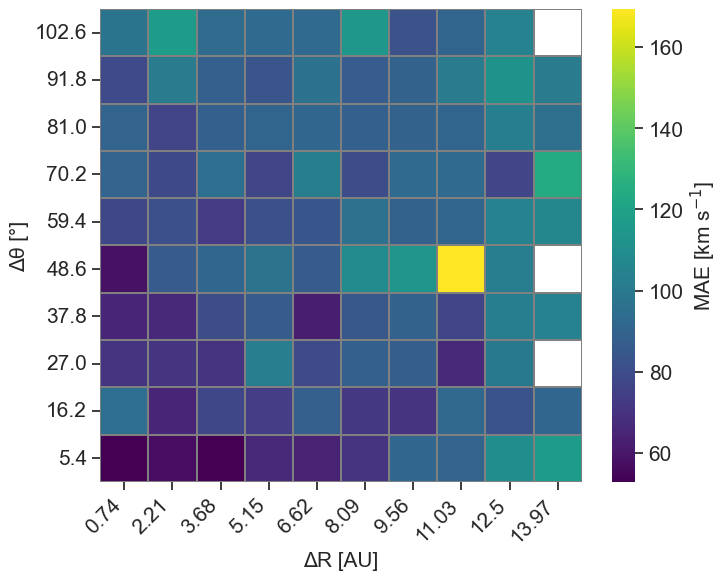

In [10]:
import pandas as pd
import seaborn as sns
from P2D import dataloader
from P2D import P2D_plots
import matplotlib.pyplot as plt
from P2D.utils import spacecraft_ID
import numpy as np
from scipy.stats import linregress
sns.set(
    style="ticks",
    palette="muted",
    rc={
        "axes.labelsize": 15,    # Axis label size
        "xtick.labelsize": 15,   # X-axis tick label size
        "ytick.labelsize": 15,   # Y-axis tick label size
        "font.size": 13,         # Overall font size
        "figure.dpi": 100,        # Dots per inch for figure quality
        "legend.fontsize": 15 # Size of legend
    }
)


# OMNI

spacecraft_to_compare = 'OMNI'

res1 = pd.read_parquet('model_cutouts/model_results_omni_2h_smoothed_inelastic_100dwindow_part1.parquet')
res2 = pd.read_parquet('model_cutouts/model_results_omni_2h_smoothed_inelastic_100dwindow_part2.parquet')
res3 = pd.read_parquet('model_cutouts/model_results_omni_2h_smoothed_inelastic_100dwindow_part3.parquet')
res4 = pd.read_parquet('model_cutouts/model_results_omni_2h_smoothed_inelastic_100dwindow_part4.parquet')
res5 = pd.read_parquet('model_cutouts/model_results_omni_2h_smoothed_inelastic_100dwindow_part5.parquet')
res6 = pd.read_parquet('model_cutouts/model_results_omni_2h_smoothed_inelastic_100dwindow_part6.parquet')
res7 = pd.read_parquet('model_cutouts/model_results_omni_2h_smoothed_inelastic_100dwindow_part7.parquet')


res = pd.concat([res1, res2, res3, res4, res5, res6, res7]).drop_duplicates(keep='first')


#res['Time'] = res.index
#res.set_index('Encounter_time', inplace=True)
time = [res.index[0], res.index[-1]]

omni = dataloader.load(spacecraft=spacecraft_to_compare, timerange=time)
omni = omni[~omni.index.duplicated(keep='first')]
omni = omni.rolling('1d').mean()

remove_cmes=True
if remove_cmes:
    cmes = pd.read_excel('HELIO4CAST_ICMECAT_v23 (1).xlsx')

    spacecraft = ['Wind', 'STEREO-A', 'SolarOrbiter', 'PSP']
    my_spacecraft = ['OMNI', 'STEREO-A', 'SolO', 'PSP']

    for i, sc in enumerate(spacecraft):
        print(sc, ' => ', my_spacecraft[i])
        start_times = pd.to_datetime(cmes.loc[cmes['sc_insitu']==sc]['icme_start_time']).reset_index()['icme_start_time'] - pd.Timedelta(value='6h')
        end_times = pd.to_datetime(cmes.loc[cmes['sc_insitu']==sc]['mo_end_time']).reset_index()['mo_end_time'] + pd.Timedelta(value='6h')

        mask = res['Spacecraft_ID']==spacecraft_ID(my_spacecraft[i], ID_number=True)

        for j in range(len(start_times)):
            
            start = start_times[j].round("h").tz_localize(None)
            end = end_times[j].round("h").tz_localize(None)

            time_mask = (mask.index < end) & (mask.index > start)


            print(start, end, time_mask.sum())
            res[time_mask] = np.nan


#Times
#res['Time'] = res.index
res['Radial_travel_time'] = (res['Time'] - res['Start_time_of_parcel']).dt.total_seconds()/3600/24
res['Persistence_time'] = (res.index - res['Time']).dt.total_seconds()/3600/24
res['Total_time_difference'] = (res.index - res['Start_time_of_parcel']).dt.total_seconds()/3600/24
res['R_difference'] = (res['R'] - res['Start_R_of_parcel'])
# mask = ((res['Spacecraft_ID'] == spacecraft_ID(spacecraft_to_compare, ID_number=True))
#          | (res['Persistence_time'] < 5))
# omni = res[mask]
# omni = omni[~omni.index.duplicated(keep='first')]
#Lat
res['LAT_difference'] = abs(res['LAT'] - res.index.map(omni['LAT']))


########################################################################################

mask = ((res['Spacecraft_ID'] != spacecraft_ID(spacecraft_to_compare, ID_number=True))
         | (res['Persistence_time'] > 20))
res = res[mask]

# mask = (res['Persistence_time'] < 27)
# res = res[mask]

########################################################################################


y='Persistence_time'
x='LAT_difference'
#x='R_difference'

res['V_Measured'] = res.index.map(omni['V'])

res = res.reset_index(drop=True)


bins = 10
binx = (res[x].max() - res[x].min()) / bins
biny = (res[y].max() - res[y].min()) / bins

# Initialize metric matrix
metric = np.full((bins, bins), np.nan)

# Loop over bins
for i in range(bins):
    for j in range(bins):
        
        x_min = res[x].min() + binx * i
        x_max = res[x].min() + binx * (i + 1)
        y_min = res[y].min() + biny * j
        y_max = res[y].min() + biny * (j + 1)

        mask = (
            (res[x] > x_min) & (res[x] <= x_max) &
            (res[y] > y_min) & (res[y] <= y_max)
        )
        subset = res[mask]

        if len(subset) >= 10:  # Need at least 2 points for regression
            x_data = subset['V'].to_numpy()
            y_data = subset['V_Measured'].to_numpy()
            valid = ~np.isnan(x_data) & ~np.isnan(y_data)
            if np.sum(valid) >= 10:
                slope, intercept, r_value, p_value, std_err = linregress(
                    x_data[valid], y_data[valid])
                mae = abs(x_data[valid] -  y_data[valid]).mean()
                rmse = np.sqrt(np.sum((x_data[valid] -  y_data[valid])**2)/np.sum(valid)).mean()
                metric[j, i] = mae


# Define bin centers for labeling
x_centers = [res[x].min() + (i + 0.5) * binx for i in range(bins)]
y_centers = [res[y].min() + (j + 0.5) * biny for j in range(bins)]


from scipy.ndimage import gaussian_filter

# Apply 2D Gaussian smoothing
smoothed_metric = gaussian_filter(metric, sigma=1)  # adjust sigma to control smoothness

# Create the plot
plt.figure(figsize=(7.5, 6))
ax = sns.heatmap(metric, cmap='viridis', cbar_kws={'label': r'MAE [km s$^{-1}$]'}, 
                 xticklabels=np.round(x_centers, 2),
                 yticklabels=np.round(y_centers, 2),
                 linewidths=0.05, linecolor='gray')

# Set axis labels and title
ax.set_xlabel(x)
ax.set_ylabel(y)

ax.set_xlabel('ΔR [AU]')
#ax.set_ylabel('Δt [d]')
ax.set_ylabel('Δθ [°]')

#ax.set_title('2D Map of Linear Regression R')

# Rotate tick labels for readability
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
ax.invert_yaxis()


plt.tight_layout()
plt.show()

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Create LAT and TIME grids
LAT = x_centers
TIME = y_centers
LAT_grid, TIME_grid = np.meshgrid(LAT, TIME)

# Compute MAE for each combination
MAE_LAT = 2.2 * LAT_grid# + 70
MAE_TIME = 8.7 * np.log(TIME_grid + 1)  # +1 to avoid log(0)
#MAE_LAT = TIME_grid *0  # +1 to avoid log(0)

MAE_LAT_TIME = MAE_LAT + MAE_TIME #+ 38.6


x = metric.flatten()
y = MAE_LAT_TIME.flatten()
mask = ~np.isnan(x)


slope, intercept, r_value, p_value, std_err = linregress(y[mask], x[mask])

# Compute intercept standard error
x_mean = np.mean(x[mask])
Sxx = np.sum((x[mask] - x_mean)**2)
intercept_stderr = std_err * np.sqrt(np.sum(x[mask]**2)/Sxx)

print(f"r_value: {r_value:.2f}")
print(f"Intercept: {intercept:.2f}")
print(f"Intercept stderr: {intercept_stderr:.2f}")


# # Plot heatmap
# plt.figure(figsize=(7.5, 6))
# ax = sns.heatmap(
#     MAE_LAT_TIME,
#     cmap='viridis',
#     cbar_kws={'label': 'MAE [km/s]'},
#     xticklabels=np.round(LAT, 1),
#     yticklabels=np.round(TIME, 1),
#     linewidths=0.05,
#     linecolor='gray'
# )

# # Labels and formatting
# ax.set_xlabel('LAT [°]')
# ax.set_ylabel('TIME [d]')
# ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
# ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
# ax.invert_yaxis()

# plt.tight_layout()
# plt.show()


propagating spacecraft data:   0%|          | 0/5 [00:00<?, ?it/s]

OMNI:   0%|          | 0/361 [00:00<?, ?it/s]

STEREO-A:   0%|          | 0/361 [00:00<?, ?it/s]

SolO:   0%|          | 0/361 [00:00<?, ?it/s]

PSP:   0%|          | 0/361 [00:00<?, ?it/s]

MAVEN:   0%|          | 0/361 [00:00<?, ?it/s]

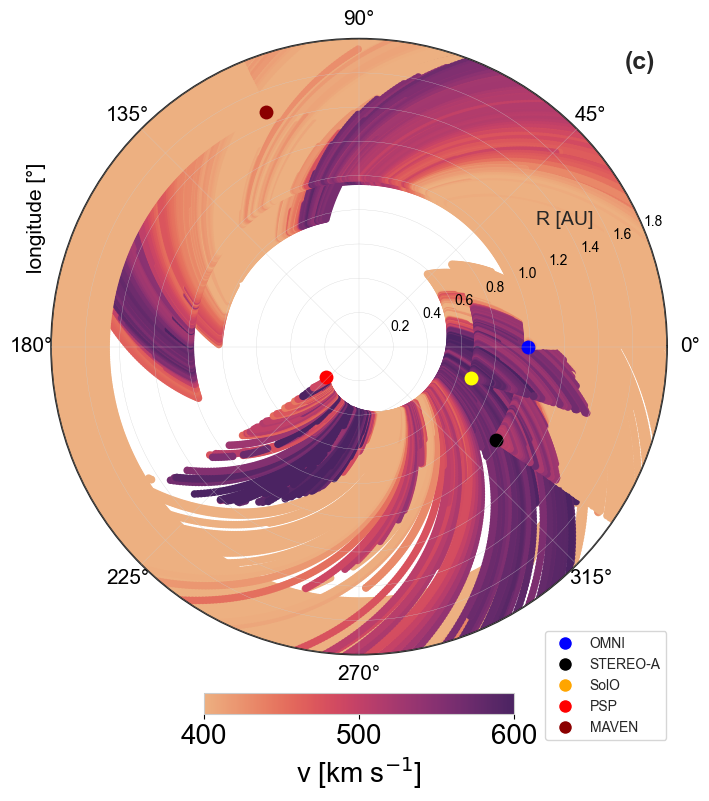

In [16]:
from P2D import P2D
import seaborn as sns
import matplotlib.pyplot as plt
# Set a single font size for everything
fontsize = 15

sns.set(
    style="ticks",
    palette="muted",
    rc={
        "font.size": fontsize,          # Base font size for everything
        "axes.titlesize": fontsize,     # Axes title
        "axes.labelsize": fontsize,     # Axes labels
        "xtick.labelsize": fontsize,    # X ticks
        "ytick.labelsize": fontsize/1.5,    # Y ticks
        "legend.fontsize": fontsize,    # Legend text
        "figure.titlesize": fontsize,   # Figure title
        "figure.dpi": 100              # Figure quality
    }
)

timerange=['2022-2-5', '2022-2-20']

model = P2D.P2D(input_data=['OMNI', 'STEREO-A', 'SolO', 'PSP', 'MAVEN']
                , timerange=timerange
                , propagation_time='10d'
                , model_type='inelastic'
                , degree_resolution=0.5, smooth = '1h', seperate_models=True)#, coordinate_system='other')


# Create polar figure
fig, ax = plt.subplots(figsize=(10, 10), subplot_kw={"projection": "polar"})

# Plot your model
model.plot(rlim=1.8, fighandle=fig, axhandle=ax)

# Customize legend
labels = ['OMNI', 'STEREO-A', 'SolO', 'PSP', 'MAVEN']
colors = ['blue', 'black', 'orange', 'red', 'darkred']

# Create custom legend handles
from matplotlib.lines import Line2D
# Create custom legend handles with dots
handles = [Line2D([0], [0], marker='o', color='w', markerfacecolor=color, markersize=10) 
           for color in colors]

# Add legend to plot
ax.legend(handles, labels, loc='lower right', bbox_to_anchor=(1.01, -0.15), frameon=True)

ax.text(
    0.98, 0.98, '(c)',
    transform=ax.transAxes,
    ha='right', va='top',
    fontsize=18, fontweight='bold'
)

ax.text(
    0.88, 0.72, 'R [AU]',
    transform=ax.transAxes,
    ha='right', va='top',
    fontsize=14
)

plt.show()


In [19]:
model.model['Index'].max()

360.0

propagating spacecraft data:   0%|          | 0/1 [00:00<?, ?it/s]

OMNI:   0%|          | 0/31 [00:00<?, ?it/s]

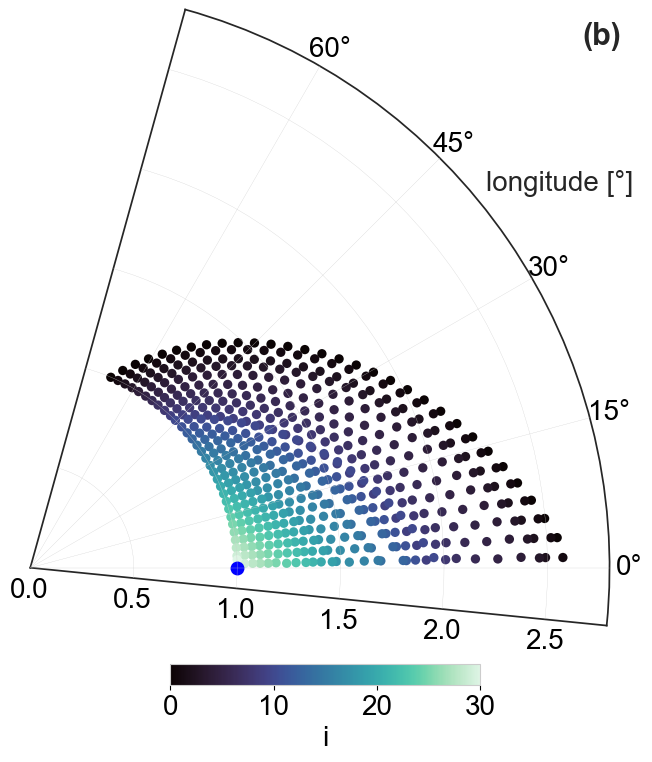

In [2]:
from P2D import P2D
import seaborn as sns
import matplotlib.pyplot as plt
# Set a single font size for everything
fontsize = 20

sns.set(
    style="ticks",
    palette="muted",
    rc={
        "font.size": fontsize,          # Base font size for everything
        "axes.titlesize": fontsize,     # Axes title
        "axes.labelsize": fontsize,     # Axes labels
        "xtick.labelsize": fontsize,    # X ticks
        "ytick.labelsize": fontsize,    # Y ticks
        "legend.fontsize": fontsize,    # Legend text
        "figure.titlesize": fontsize,   # Figure title
        "figure.dpi": 100              # Figure quality
    }
)


timerange=['2022-4-2', '2022-4-7']

model = P2D.P2D(input_data=['OMNI']
                , timerange=timerange
                , propagation_time='5d'
                , model_type='ballistic'
                , degree_resolution=2, smooth = '1h', seperate_models=True)#, coordinate_system='other')


# Create polar figure
fig, ax = plt.subplots(figsize=(10, 10), subplot_kw={"projection": "polar"})

ax.title.set_fontsize(20)
ax.xaxis.label.set_fontsize(20)
ax.yaxis.label.set_fontsize(20)
ax.tick_params(labelsize=20)
# Plot your model
model.plot(rlim=2.8, fighandle=fig, axhandle=ax, variable_to_plot='i', s=15)
#model.plot(rlim=2.8, fighandle=fig, axhandle=ax, s=15)

ax.set_ylabel('')
ax.set_xlim(-0.1, 1.3)

ax.text(
    0.98, 0.98, '(b)',
    transform=ax.transAxes,
    ha='right', va='top',
    fontsize=22, fontweight='bold'
)

ax.text(
    1, 0.74, 'longitude [°]',
    transform=ax.transAxes,
    ha='right', va='top',
    fontsize=20
)

plt.show()


In [5]:
from P2D import dataloader

data = dataloader.load(spacecraft='OMNI', timerange=['2020', '2024'])
dis = abs(data['V']-(data['V'].mean()))
dis.mean()

71.01016147512367

In [ ]:
from P2D import P2D
import seaborn as sns
import matplotlib.pyplot as plt
# Set a single font size for everything
fontsize = 15

sns.set(
    style="ticks",
    palette="muted",
    rc={
        "font.size": fontsize,          # Base font size for everything
        "axes.titlesize": fontsize,     # Axes title
        "axes.labelsize": fontsize,     # Axes labels
        "xtick.labelsize": fontsize,    # X ticks
        "ytick.labelsize": fontsize/1.5,    # Y ticks
        "legend.fontsize": fontsize,    # Legend text
        "figure.titlesize": fontsize,   # Figure title
        "figure.dpi": 100              # Figure quality
    }
)

timerange=['2022-11-1', '2023-2-01']

model = P2D.P2D(input_data=['OMNI', 'STEREO-A', 'SolO', 'PSP', 'MAVEN']
                , timerange=timerange
                , propagation_time='15d'
                , model_type='inelastic'
                , degree_resolution=0.5, smooth = '1h', seperate_models=True)#, coordinate_system='other')


#model.plot(rlim=1.8, fighandle=fig, axhandle=ax)

plt.show()


propagating spacecraft data:   0%|          | 0/5 [00:00<?, ?it/s]

OMNI:   0%|          | 0/2209 [00:00<?, ?it/s]

STEREO-A:   0%|          | 0/2209 [00:00<?, ?it/s]

SolO:   0%|          | 0/2208 [00:00<?, ?it/s]

PSP:   0%|          | 0/2198 [00:00<?, ?it/s]

MAVEN:   0%|          | 0/2208 [00:00<?, ?it/s]

AttributeError: 'numpy.ndarray' object has no attribute 'yaxis'

FIRST CUTTING OUT TIMESERIES FROM ['MAVEN', 'OMNI'] PERSPECTIVE
MAVEN


  0%|          | 0/2320 [00:00<?, ?it/s]

OMNI


  0%|          | 0/2320 [00:00<?, ?it/s]

Animating:   0%|          | 0/1105 [00:00<?, ?it/s]

c:\Users\14milosi\AppData\Local\anaconda3\envs\Solar\Lib\site-packages\matplotlib\axes\_base.py:2503: UserWarning: Warning: converting a masked element to nan.
  xys = np.asarray(xys)
c:\Users\14milosi\AppData\Local\anaconda3\envs\Solar\Lib\site-packages\matplotlib\axes\_base.py:2503: UserWarning: Warning: converting a masked element to nan.
  xys = np.asarray(xys)
c:\Users\14milosi\AppData\Local\anaconda3\envs\Solar\Lib\site-packages\matplotlib\axes\_base.py:2503: UserWarning: Warning: converting a masked element to nan.
  xys = np.asarray(xys)


2023-01-26 04:00:00 NO DATA, DOWNLOADING PSP POSITION
2023-01-26 10:00:00 NO DATA, DOWNLOADING PSP POSITION
2023-01-26 12:00:00 NO DATA, DOWNLOADING PSP POSITION
2023-01-26 14:00:00 NO DATA, DOWNLOADING PSP POSITION
2023-01-26 16:00:00 NO DATA, DOWNLOADING PSP POSITION
2023-01-26 18:00:00 NO DATA, DOWNLOADING PSP POSITION
2023-01-26 20:00:00 NO DATA, DOWNLOADING PSP POSITION
2023-01-26 22:00:00 NO DATA, DOWNLOADING PSP POSITION
2023-01-27 00:00:00 NO DATA, DOWNLOADING PSP POSITION
2023-01-27 06:00:00 NO DATA, DOWNLOADING PSP POSITION
2023-01-27 08:00:00 NO DATA, DOWNLOADING PSP POSITION
2023-01-27 10:00:00 NO DATA, DOWNLOADING PSP POSITION
2023-01-27 12:00:00 NO DATA, DOWNLOADING PSP POSITION
2023-01-27 14:00:00 NO DATA, DOWNLOADING PSP POSITION
2023-01-27 20:00:00 NO DATA, DOWNLOADING PSP POSITION
2023-01-27 22:00:00 NO DATA, DOWNLOADING PSP POSITION
2023-01-28 00:00:00 NO DATA, DOWNLOADING PSP POSITION
2023-01-28 02:00:00 NO DATA, DOWNLOADING PSP POSITION
2023-01-28 04:00:00 NO DATA,

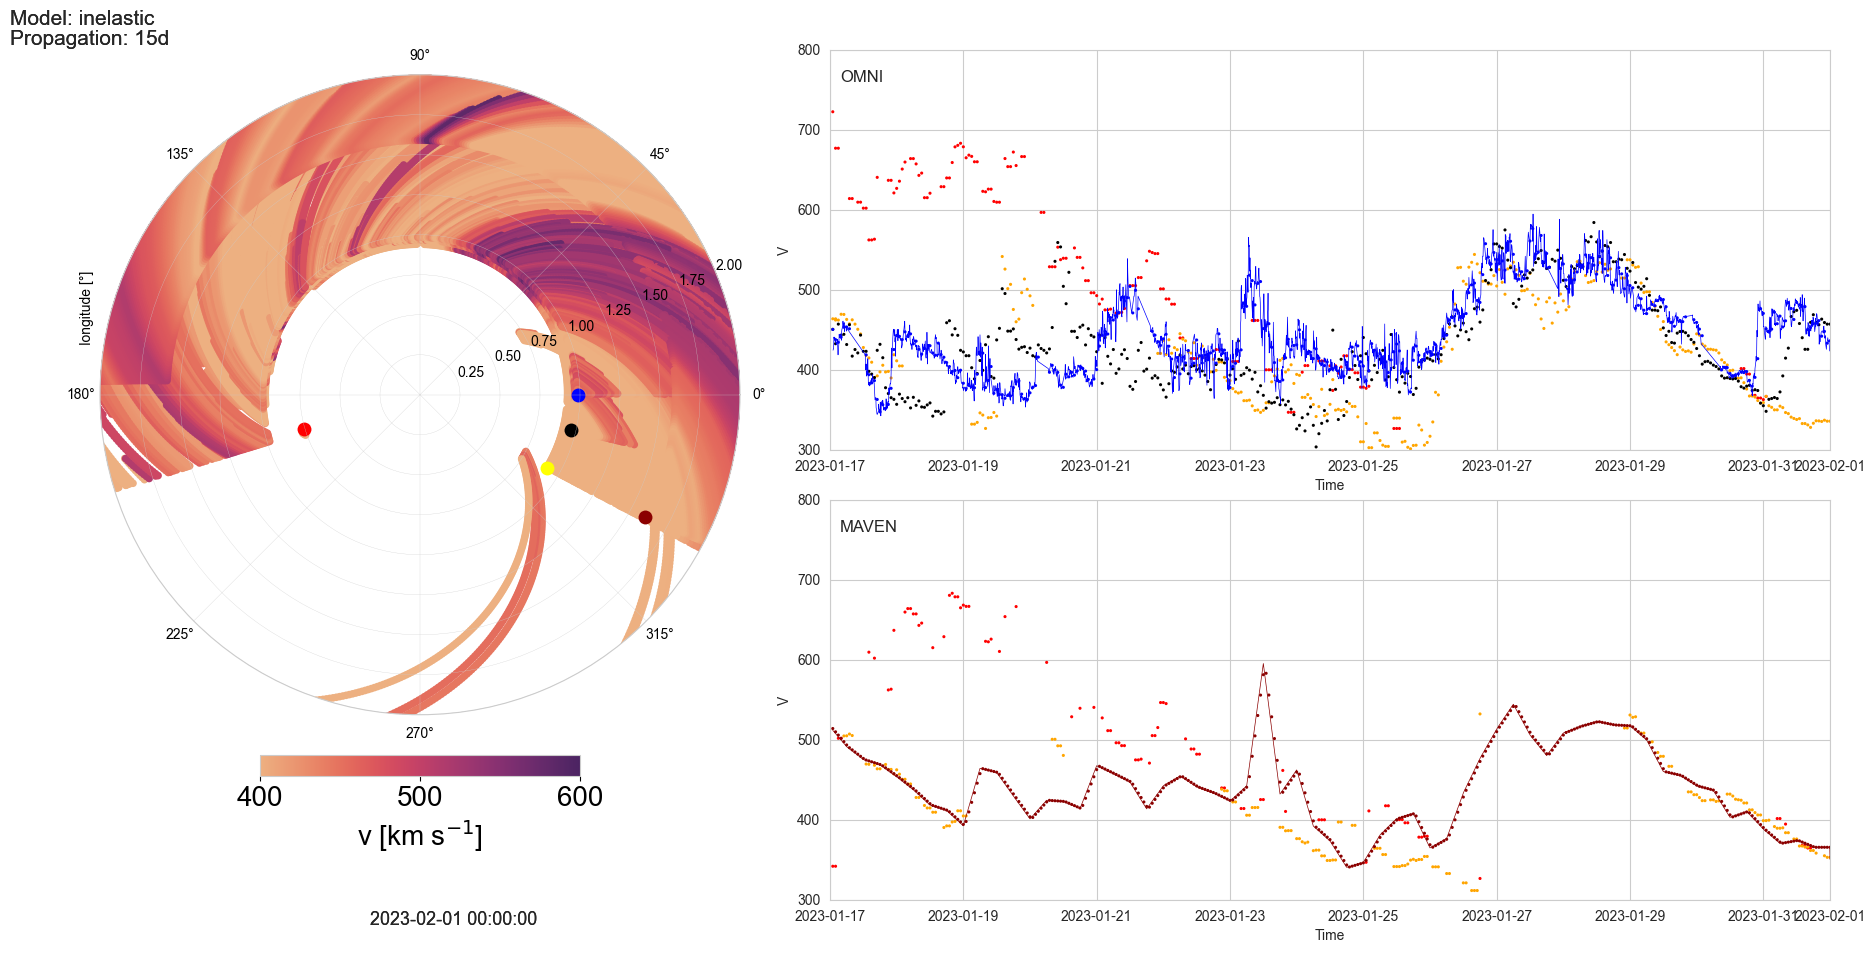

In [9]:
model.movie(cadence='2h', rlim=2, time_window='15d', observers=['MAVEN', 'OMNI'], frametrate=30, name='PAPER', plot_against_time=True)

[Info] Attempting download from https://raw.githubusercontent.com/danielmilosic/DRaD/master/reduced_data/omni/omni_data2024-09.parquet
[Warning] Skipping 2024-09: GitHub file not available (404)
Wind  =>  OMNI
2024-12-16 22:00:00 2024-12-17 20:00:00 0
2024-12-07 17:00:00 2024-12-09 00:00:00 0
2024-11-28 20:00:00 2024-11-29 23:00:00 0
2024-11-13 21:00:00 2024-11-14 22:00:00 0
2024-11-09 16:00:00 2024-11-10 17:00:00 0
2024-11-08 16:00:00 2024-11-09 18:00:00 0
2024-11-08 04:00:00 2024-11-09 01:00:00 0
2024-10-26 10:00:00 2024-10-27 15:00:00 55
2024-10-10 09:00:00 2024-10-11 16:00:00 37
2024-10-07 16:00:00 2024-10-08 15:00:00 22
2024-10-07 06:00:00 2024-10-08 02:00:00 19
2024-10-06 01:00:00 2024-10-07 07:00:00 29
2024-09-16 17:00:00 2024-09-17 18:00:00 23
2024-09-12 02:00:00 2024-09-13 06:00:00 27
2024-09-11 21:00:00 2024-09-12 14:00:00 16
2024-08-31 06:00:00 2024-09-01 15:00:00 117
2024-08-27 02:00:00 2024-08-29 22:00:00 253
2024-08-17 08:00:00 2024-08-18 15:00:00 94
2024-08-10 06:00:00 2

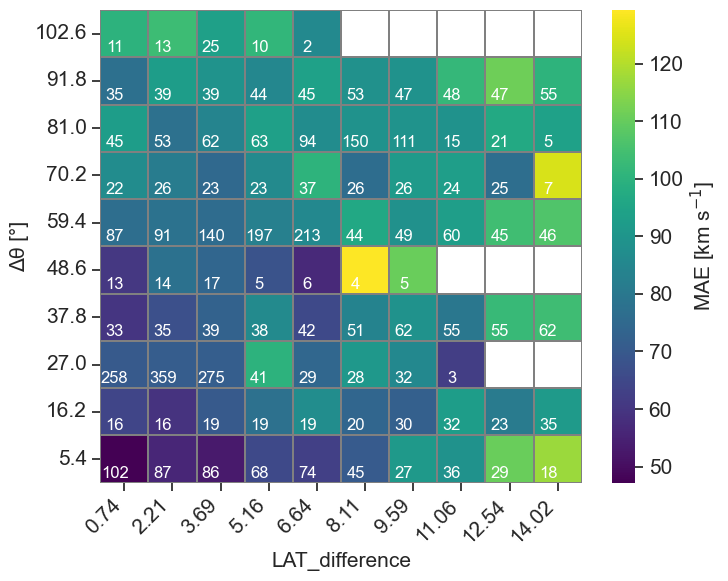

In [4]:
import pandas as pd
import seaborn as sns
from P2D import dataloader
from P2D import P2D_plots
import matplotlib.pyplot as plt
from P2D.utils import spacecraft_ID
import numpy as np
from scipy.stats import linregress
sns.set(
    style="ticks",
    palette="muted",
    rc={
        "axes.labelsize": 15,    # Axis label size
        "xtick.labelsize": 15,   # X-axis tick label size
        "ytick.labelsize": 15,   # Y-axis tick label size
        "font.size": 13,         # Overall font size
        "figure.dpi": 100,        # Dots per inch for figure quality
        "legend.fontsize": 15 # Size of legend
    }
)


# OMNI

spacecraft_to_compare = 'OMNI'

res1 = pd.read_parquet('model_cutouts/model_results_omni_2h_smoothed_inelastic_100dwindow_part1.parquet')
res2 = pd.read_parquet('model_cutouts/model_results_omni_2h_smoothed_inelastic_100dwindow_part2.parquet')
res3 = pd.read_parquet('model_cutouts/model_results_omni_2h_smoothed_inelastic_100dwindow_part3.parquet')
res4 = pd.read_parquet('model_cutouts/model_results_omni_2h_smoothed_inelastic_100dwindow_part4.parquet')
res5 = pd.read_parquet('model_cutouts/model_results_omni_2h_smoothed_inelastic_100dwindow_part5.parquet')
res6 = pd.read_parquet('model_cutouts/model_results_omni_2h_smoothed_inelastic_100dwindow_part6.parquet')
res7 = pd.read_parquet('model_cutouts/model_results_omni_2h_smoothed_inelastic_100dwindow_part7.parquet')


res = pd.concat([res1, res2, res3, res4, res5, res6, res7]).drop_duplicates(keep='first')


#res['Time'] = res.index
#res.set_index('Encounter_time', inplace=True)
time = [res.index[0], res.index[-1]]

omni = dataloader.load(spacecraft=spacecraft_to_compare, timerange=time)
omni = omni[~omni.index.duplicated(keep='first')]
omni = omni.rolling('1d').mean()

remove_cmes=True
if remove_cmes:
    cmes = pd.read_excel('HELIO4CAST_ICMECAT_v23 (1).xlsx')

    spacecraft = ['Wind', 'STEREO-A', 'SolarOrbiter', 'PSP']
    my_spacecraft = ['OMNI', 'STEREO-A', 'SolO', 'PSP']

    for i, sc in enumerate(spacecraft):
        print(sc, ' => ', my_spacecraft[i])
        start_times = pd.to_datetime(cmes.loc[cmes['sc_insitu']==sc]['icme_start_time']).reset_index()['icme_start_time'] - pd.Timedelta(value='6h')
        end_times = pd.to_datetime(cmes.loc[cmes['sc_insitu']==sc]['mo_end_time']).reset_index()['mo_end_time'] + pd.Timedelta(value='6h')

        mask = res['Spacecraft_ID']==spacecraft_ID(my_spacecraft[i], ID_number=True)

        for j in range(len(start_times)):
            
            start = start_times[j].round("h").tz_localize(None)
            end = end_times[j].round("h").tz_localize(None)

            time_mask = (mask.index < end) & (mask.index > start)


            print(start, end, time_mask.sum())
            res[time_mask] = np.nan


#Times
#res['Time'] = res.index
res['Radial_travel_time'] = (res['Time'] - res['Start_time_of_parcel']).dt.total_seconds()/3600/24
res['Persistence_time'] = (res.index - res['Time']).dt.total_seconds()/3600/24
res['Total_time_difference'] = (res.index - res['Start_time_of_parcel']).dt.total_seconds()/3600/24
res['R_difference'] = (res['R'] - res['Start_R_of_parcel'])
# mask = ((res['Spacecraft_ID'] == spacecraft_ID(spacecraft_to_compare, ID_number=True))
#          | (res['Persistence_time'] < 5))
# omni = res[mask]
# omni = omni[~omni.index.duplicated(keep='first')]
#Lat
res['LAT_difference'] = abs(res['LAT'] - res.index.map(omni['LAT']))


########################################################################################

mask = ((res['Spacecraft_ID'] != spacecraft_ID(spacecraft_to_compare, ID_number=True))
         | (res['Persistence_time'] > 20))
res = res[mask]

# mask = (res['Persistence_time'] < 27)
# res = res[mask]

########################################################################################


y='Persistence_time'
x='LAT_difference'
#x='R_difference'

res['V_Measured'] = res.index.map(omni['V'])

res = res.reset_index(drop=True)


bins = 10
binx = (res[x].max() - res[x].min()) / bins
binx = (res[x].max() - res[x].min()) / bins
biny = (res[y].max() - res[y].min()) / bins

# Initialize metric matrix
metric = np.full((bins, bins), np.nan)
counts = np.full((bins, bins), np.nan)

# Loop over bins
for i in range(bins):
    for j in range(bins):
        
        x_min = res[x].min() + binx * i
        x_max = res[x].min() + binx * (i + 1)
        y_min = res[y].min() + biny * j
        y_max = res[y].min() + biny * (j + 1)

        mask = (
            (res[x] > x_min) & (res[x] <= x_max) &
            (res[y] > y_min) & (res[y] <= y_max)
        )
        subset = res[mask]

        if len(subset) >= 100:  # Need at least 2 points for regression
            x_data = subset['V'].to_numpy()
            y_data = subset['V_Measured'].to_numpy()
            valid = ~np.isnan(x_data) & ~np.isnan(y_data)
            if np.sum(valid) >= 10:
                slope, intercept, r_value, p_value, std_err = linregress(
                    x_data[valid], y_data[valid])
                mae = abs(x_data[valid] -  y_data[valid]).mean()
                #if i==7 and j==4:mae=np.nan
                rmse = np.sqrt(np.sum((x_data[valid] -  y_data[valid])**2)/np.sum(valid)).mean()
                metric[j, i] = mae
                counts[j, i] = int(round(np.sum(valid/100)))


# Define bin centers for labeling
x_centers = [res[x].min() + (i + 0.5) * binx for i in range(bins)]
y_centers = [res[y].min() + (j + 0.5) * biny for j in range(bins)]


from scipy.ndimage import gaussian_filter

# Apply 2D Gaussian smoothing
smoothed_metric = gaussian_filter(metric, sigma=1)  # adjust sigma to control smoothness

# Create the plot
plt.figure(figsize=(7.5, 6))
ax = sns.heatmap(metric, cmap='viridis', cbar_kws={'label': r'MAE [km s$^{-1}$]'}, 
                 xticklabels=np.round(x_centers, 2),
                 yticklabels=np.round(y_centers, 2),
                 linewidths=0.05, linecolor='gray')

# Set axis labels and title
ax.set_xlabel(x)
ax.set_ylabel(y)

#ax.set_xlabel('ΔR [AU]')
ax.set_ylabel('Δt [d]')
ax.set_ylabel('Δθ [°]')

#ax.set_title('2D Map of Linear Regression R')

# Rotate tick labels for readability
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
ax.invert_yaxis()

# --- Annotate each heatmap square with bin counts ---
for i in range(metric.shape[0]):
    for j in range(metric.shape[1]):
        ax.text(j + 0.3, i + 0.2, f'{counts[i, j]:.0f}',
                ha='center', va='center', color='white', fontsize=12)


plt.tight_layout()
plt.show()

In [8]:
len(omni['V'])

924102

r =  -0.0010213266889047112 MAE =  97.76468037087821 ME =  0.03471764971110082


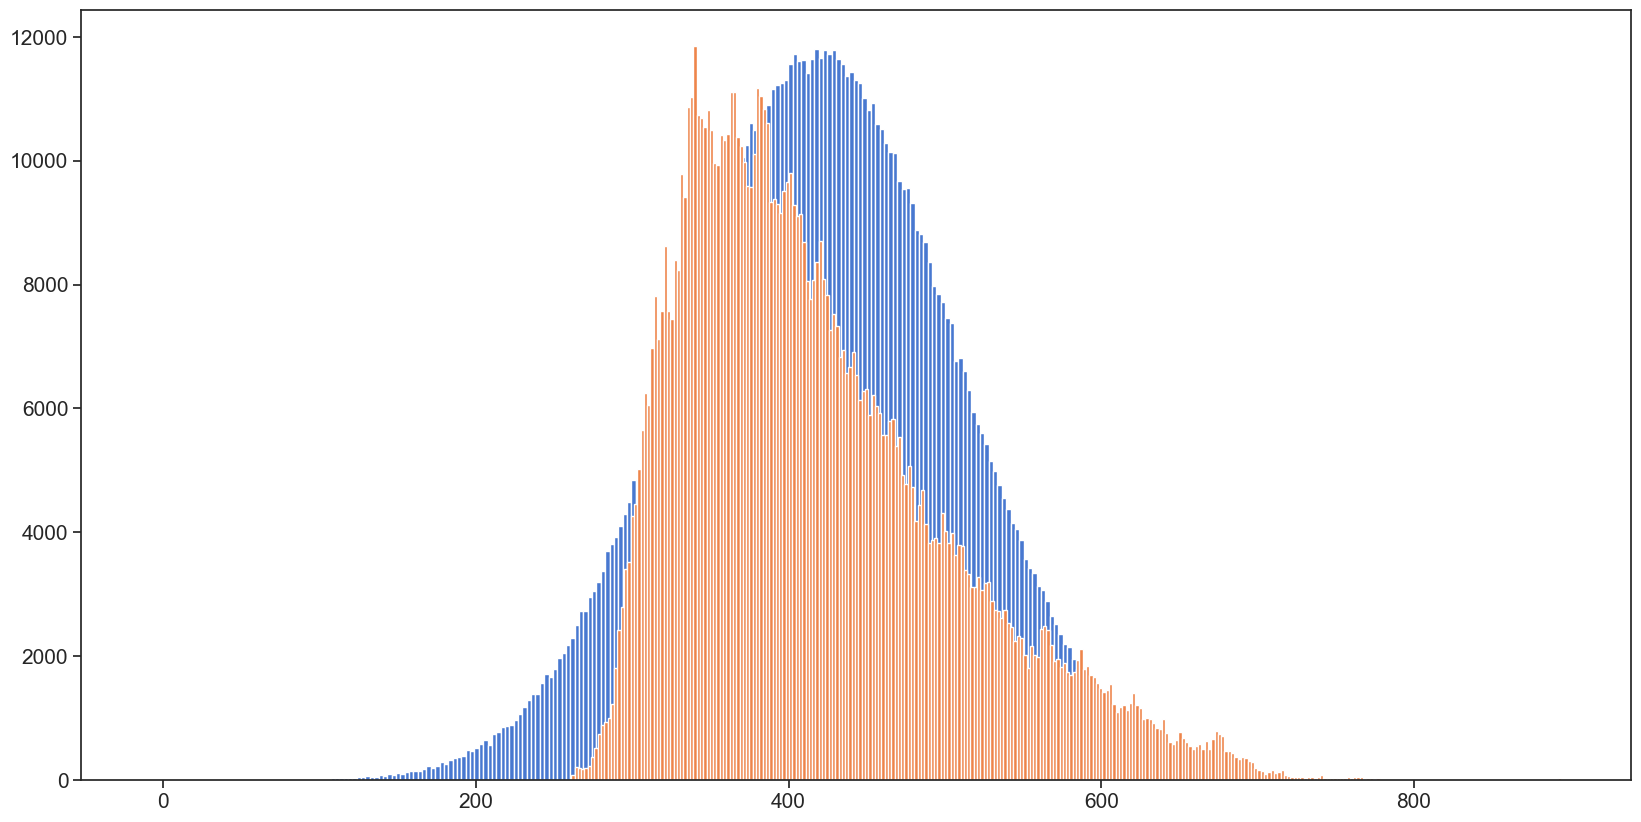

In [22]:
import numpy as np

omni.dropna(subset='V', inplace=True)

omni['RANDOM'] = np.random.normal(loc=omni['V'].mean(), scale=omni['V'].std(), size=len(omni['V']))


MAE = abs(omni['V'] - omni['RANDOM']).mean()
ME = (omni['V'] - omni['RANDOM']).mean()

slope, intercept, r, p_value, std_err = linregress(omni['V'], omni['RANDOM'])


print('r = ', r, 'MAE = ', MAE, 'ME = ', ME)

fig = plt.figure(figsize=(20,10))
plt.hist(omni['RANDOM'], bins=300)
plt.hist(omni['V'], bins=300)

plt.show()

r =  0.0006899129771255469 MAE =  97.59066518454578 ME =  0.052112516897013454


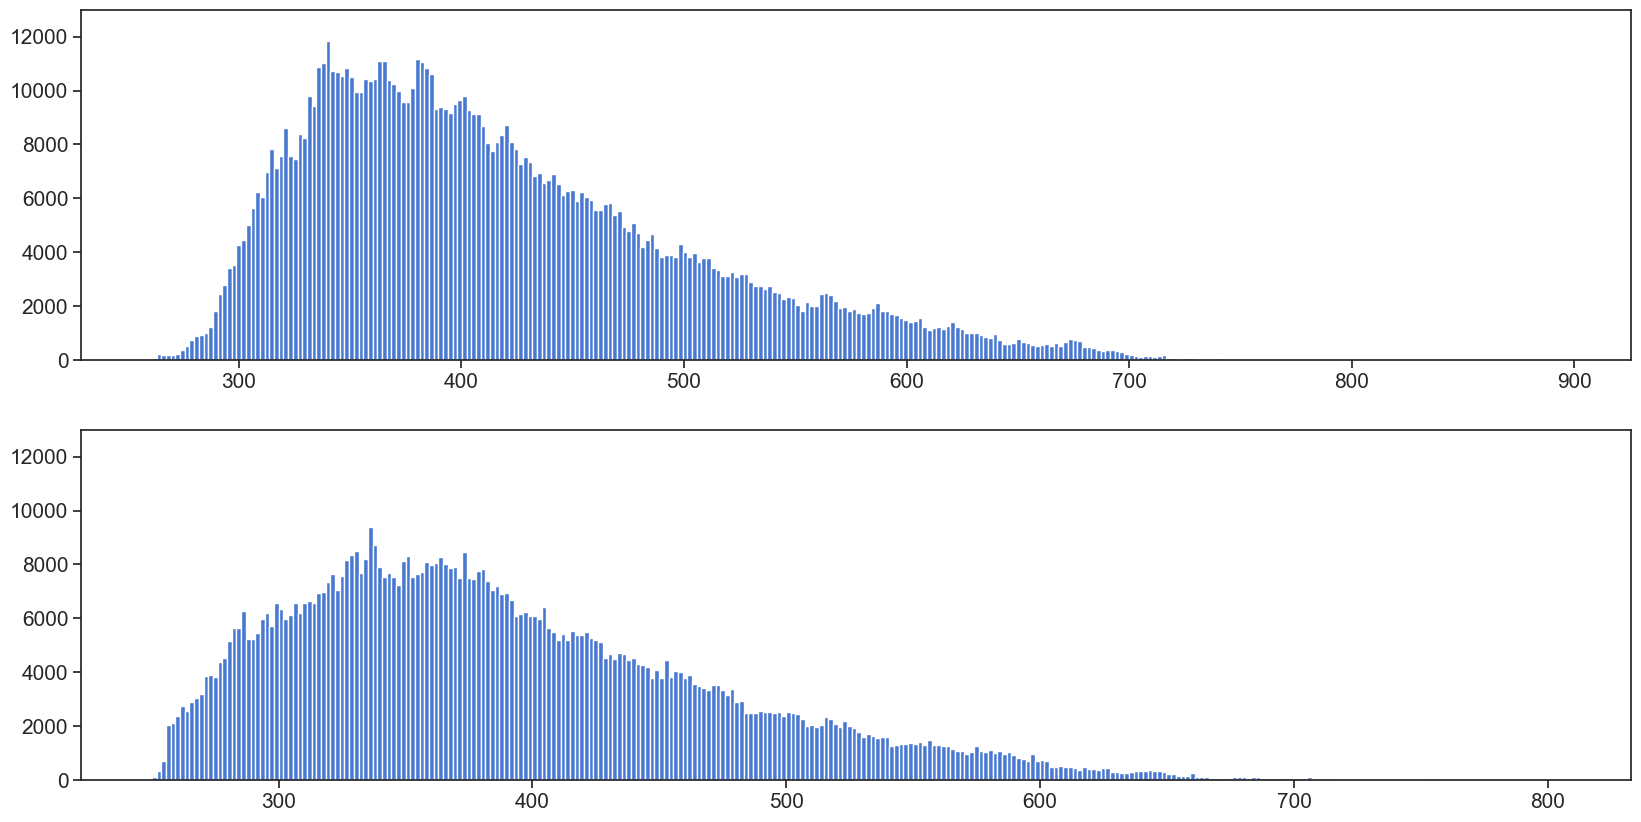

In [36]:
import numpy as np

omni.dropna(subset='V', inplace=True)

omni['RANDOM'] = np.random.normal(loc=omni['V'].mean(), scale=omni['V'].std(), size=len(omni['V']))


MAE = abs(omni['V'] - omni['RANDOM']).mean()
ME = (omni['V'] - omni['RANDOM']).mean()

slope, intercept, r, p_value, std_err = linregress(omni['V'], omni['RANDOM'])


print('r = ', r, 'MAE = ', MAE, 'ME = ', ME)

fig, ax = plt.subplots(figsize=(20,10), nrows=2)
#plt.hist(maven['V'], bins=300)
ax[0].hist(omni['V'], bins=300)
ax[1].hist(maven['V'], bins=300)

ax[0].set_ylim(0, 13000)
ax[1].set_ylim(0, 13000)
plt.show()

In [26]:
maven = omni.copy()